# Importation des bibliothèques

In [ ]:
!pip install keras-tuner
!pip install seaborn
!pip install scikeras

In [ ]:
# Importation des bibliothèques nécessaires à tout le projet
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler, LabelEncoder, label_binarize
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.decomposition import PCA
from sklearn.utils import resample
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, roc_curve, auc)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, LeakyReLU, ELU
from tensorflow.keras.optimizers import Adam
import keras_tuner as kt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.pipeline import Pipeline
import os
import joblib
from scikeras.wrappers import KerasClassifier
from imblearn.over_sampling import SMOTE
import xgboost as xgb
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc, ConfusionMatrixDisplay

# Configuration des graphiques
plt.style.use('ggplot')
sns.set_theme()

# Classification des Défauts sur des Plaques d'Acier

Ce projet vise à classifier différents types de défauts sur des plaques
d'acier en utilisant des techniques de machine learning et de deep learning.
Le dataset peut être trouvé sur [ce lien](https://drive.google.com/file/d/1bkAEwCUyjaHRu_Wnxdea3GY7G5meGK3P/view), et comprend des variables
numériques décrivant les caractéristiques des défauts.

Les étapes principales du projet sont :

- Présentation et exploration des données
- Préparation et nettoyage des données
- Analyse exploratoire avec visualisations
- Sélection et réduction des variables
- Entraînement et évaluation de plusieurs modèles
- Optimisation des hyperparamètres
- Sélection du modèle final et conclusions


# Chargement et Présentation des Données


In [ ]:
# Chargement du dataset
dataset_path = "/content/faults.csv"
data = pd.read_csv(dataset_path)
# Aperçu des premières lignes du dataset
print("Extrait du dataset : \n")
display(data.tail())


Extrait du dataset : 



,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Minimum_of_Luminosity,Maximum_of_Luminosity,...,Edges_X_Index,Edges_Y_Index,Outside_Global_Index,LogOfAreas,Log_X_Index,Log_Y_Index,Orientation_Index,Luminosity_Index,SigmoidOfAreas,target
1936,249,277.0,325780,325796,273,54,22,35033,119,141,...,0.5185,0.7273,0.0,2.4362,1.4472,1.2041,-0.4286,0.0026,0.7254,Other_Faults
1937,144,175.0,340581,340598,287,44,24,34599,112,133,...,0.7046,0.7083,0.0,2.4579,1.4914,1.2305,-0.4516,-0.0582,0.8173,Other_Faults
1938,145,174.0,386779,386794,292,40,22,37572,120,140,...,0.7250,0.6818,0.0,2.4654,1.4624,1.1761,-0.4828,0.0052,0.7079,Other_Faults
1939,137,170.0,422497,422528,419,97,47,52715,117,140,...,0.3402,0.6596,0.0,2.6222,1.5185,1.4914,-0.0606,-0.0171,0.9919,Other_Faults
1940,1261,1281.0,87951,87967,103,26,22,11682,101,133,...,0.7692,0.7273,0.0,2.0128,1.3010,1.2041,-0.2000,-0.1139,0.5296,Other_Faults


In [ ]:
# Dimensions du dataset
print(f"Nombre d'observations (lignes) : {data.shape[0]}")
print(f"Nombre de variables (colonnes) : {data.shape[1]}")

Nombre d'observations (lignes) : 1941
Nombre de variables (colonnes) : 28


In [ ]:
# Informations sur les types de données
print("Informations sur les types de données : \n")
data.info()

Informations sur les types de données : 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1941 entries, 0 to 1940
Data columns (total 28 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   X_Minimum              1941 non-null   int64  
 1   X_Maximum              1917 non-null   float64
 2   Y_Minimum              1941 non-null   int64  
 3   Y_Maximum              1941 non-null   int64  
 4   Pixels_Areas           1941 non-null   int64  
 5   X_Perimeter            1941 non-null   int64  
 6   Y_Perimeter            1941 non-null   int64  
 7   Sum_of_Luminosity      1941 non-null   int64  
 8   Minimum_of_Luminosity  1941 non-null   int64  
 9   Maximum_of_Luminosity  1941 non-null   int64  
 10  Length_of_Conveyer     1941 non-null   int64  
 11  TypeOfSteel_A300       1941 non-null   int64  
 12  TypeOfSteel_A400       1941 non-null   int64  
 13  Steel_Plate_Thickness  1911 non-null   float64
 14  Edges_Index   

In [ ]:
# Identification des colonnes numériques et textuelles
numerical_features = data.select_dtypes(include=[np.number]).columns.tolist()
textual_features = data.select_dtypes(include=['object']).columns.tolist()
print("Variables numériques :", numerical_features)
print("Variables textuelles :", textual_features)

Variables numériques : ['X_Minimum', 'X_Maximum', 'Y_Minimum', 'Y_Maximum', 'Pixels_Areas', 'X_Perimeter', 'Y_Perimeter', 'Sum_of_Luminosity', 'Minimum_of_Luminosity', 'Maximum_of_Luminosity', 'Length_of_Conveyer', 'TypeOfSteel_A300', 'TypeOfSteel_A400', 'Steel_Plate_Thickness', 'Edges_Index', 'Empty_Index', 'Square_Index', 'Outside_X_Index', 'Edges_X_Index', 'Edges_Y_Index', 'Outside_Global_Index', 'LogOfAreas', 'Log_X_Index', 'Log_Y_Index', 'Orientation_Index', 'Luminosity_Index', 'SigmoidOfAreas']
Variables textuelles : ['target']


# Analyse Préparatoire des Données

## Vérification des Valeurs Manquantes

In [ ]:
# Valeurs manquantes
print("\nValeurs manquantes dans le dataset :\n")
print(data.isnull().sum())


Valeurs manquantes dans le dataset :

X_Minimum                 0
X_Maximum                24
Y_Minimum                 0
Y_Maximum                 0
Pixels_Areas              0
X_Perimeter               0
Y_Perimeter               0
Sum_of_Luminosity         0
Minimum_of_Luminosity     0
Maximum_of_Luminosity     0
Length_of_Conveyer        0
TypeOfSteel_A300          0
TypeOfSteel_A400          0
Steel_Plate_Thickness    30
Edges_Index               0
Empty_Index              26
Square_Index              0
Outside_X_Index           0
Edges_X_Index             0
Edges_Y_Index             0
Outside_Global_Index      0
LogOfAreas                0
Log_X_Index               0
Log_Y_Index               0
Orientation_Index         0
Luminosity_Index          0
SigmoidOfAreas            0
target                    0
dtype: int64


In [ ]:
# Afficher les colonnes et leurs valeurs manquantes séparées
missing_data = data.isnull().sum()
# Séparer en colonnes avec et sans valeurs manquantes
columns_with_missing = missing_data[missing_data > 0]
print("\nColonnes avec des valeurs manquantes :")
print(columns_with_missing)


Colonnes avec des valeurs manquantes :
X_Maximum                24
Steel_Plate_Thickness    30
Empty_Index              26
dtype: int64


## Suppression des Valeurs Manquantes

In [ ]:
# Suppression avec KNNImputer pour les variables numériques
suppr = KNNImputer(n_neighbors=5)
data_numeric = data[numerical_features]
data_imputed = suppr.fit_transform(data_numeric)
data_cleaned = data.copy()
data_cleaned[numerical_features] = data_imputed

In [ ]:
# Vérification après imputation
print("Valeurs manquantes après suppression des lignes avec valeurs manquantes :")
print(data_cleaned.isnull().sum())

Valeurs manquantes après suppression des lignes avec valeurs manquantes :
X_Minimum                0
X_Maximum                0
Y_Minimum                0
Y_Maximum                0
Pixels_Areas             0
X_Perimeter              0
Y_Perimeter              0
Sum_of_Luminosity        0
Minimum_of_Luminosity    0
Maximum_of_Luminosity    0
Length_of_Conveyer       0
TypeOfSteel_A300         0
TypeOfSteel_A400         0
Steel_Plate_Thickness    0
Edges_Index              0
Empty_Index              0
Square_Index             0
Outside_X_Index          0
Edges_X_Index            0
Edges_Y_Index            0
Outside_Global_Index     0
LogOfAreas               0
Log_X_Index              0
Log_Y_Index              0
Orientation_Index        0
Luminosity_Index         0
SigmoidOfAreas           0
target                   0
dtype: int64


## Statistiques descriptives

In [ ]:
# Statistiques descriptives des variables numériques
print("Statistiques descriptives :\n")
display(data_cleaned[numerical_features].describe())

Statistiques descriptives :



,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Minimum_of_Luminosity,Maximum_of_Luminosity,...,Outside_X_Index,Edges_X_Index,Edges_Y_Index,Outside_Global_Index,LogOfAreas,Log_X_Index,Log_Y_Index,Orientation_Index,Luminosity_Index,SigmoidOfAreas
count,1941.000000,1941.000000,1.941000e+03,1.941000e+03,1941.000000,1941.000000,1941.000000,1.941000e+03,1941.000000,1941.000000,...,1941.000000,1941.000000,1941.000000,1941.000000,1941.000000,1941.000000,1941.000000,1941.000000,1941.000000,1941.000000
mean,571.136012,613.805152,1.650685e+06,1.650739e+06,1893.878413,111.855229,82.965997,2.063121e+05,84.548686,130.193715,...,0.033361,0.610529,0.813472,0.575734,2.492388,1.335686,1.403271,0.083288,-0.131305,0.585420
std,520.690671,493.639126,1.774578e+06,1.774590e+06,5168.459560,301.209187,426.482879,5.122936e+05,32.134276,18.690992,...,0.058961,0.243277,0.234274,0.482352,0.788930,0.481612,0.454345,0.500868,0.148767,0.339452
min,0.000000,4.000000,6.712000e+03,6.724000e+03,2.000000,2.000000,1.000000,2.500000e+02,0.000000,37.000000,...,0.001500,0.014400,0.048400,0.000000,0.301000,0.301000,0.000000,-0.991000,-0.998900,0.119000
25%,51.000000,192.000000,4.712530e+05,4.712810e+05,84.000000,15.000000,13.000000,9.522000e+03,63.000000,124.000000,...,0.006600,0.411800,0.596800,0.000000,1.924300,1.000000,1.079200,-0.333300,-0.195000,0.248200
50%,435.000000,466.000000,1.204128e+06,1.204136e+06,174.000000,26.000000,25.000000,1.920200e+04,90.000000,127.000000,...,0.010100,0.636400,0.947400,1.000000,2.240600,1.176100,1.322200,0.095200,-0.133000,0.506300
75%,1053.000000,1059.000000,2.183073e+06,2.183084e+06,822.000000,84.000000,83.000000,8.301100e+04,106.000000,140.000000,...,0.023500,0.800000,1.000000,1.000000,2.914900,1.518500,1.732400,0.511600,-0.066600,0.999800
max,1705.000000,1713.000000,1.298766e+07,1.298769e+07,152655.000000,10449.000000,18152.000000,1.159141e+07,203.000000,253.000000,...,0.875900,1.000000,1.000000,1.000000,5.183700,3.074100,4.258700,0.991700,0.642100,1.000000


# Analyse Exploratoire avec Visualisations

## Distribution des Variables Numériques

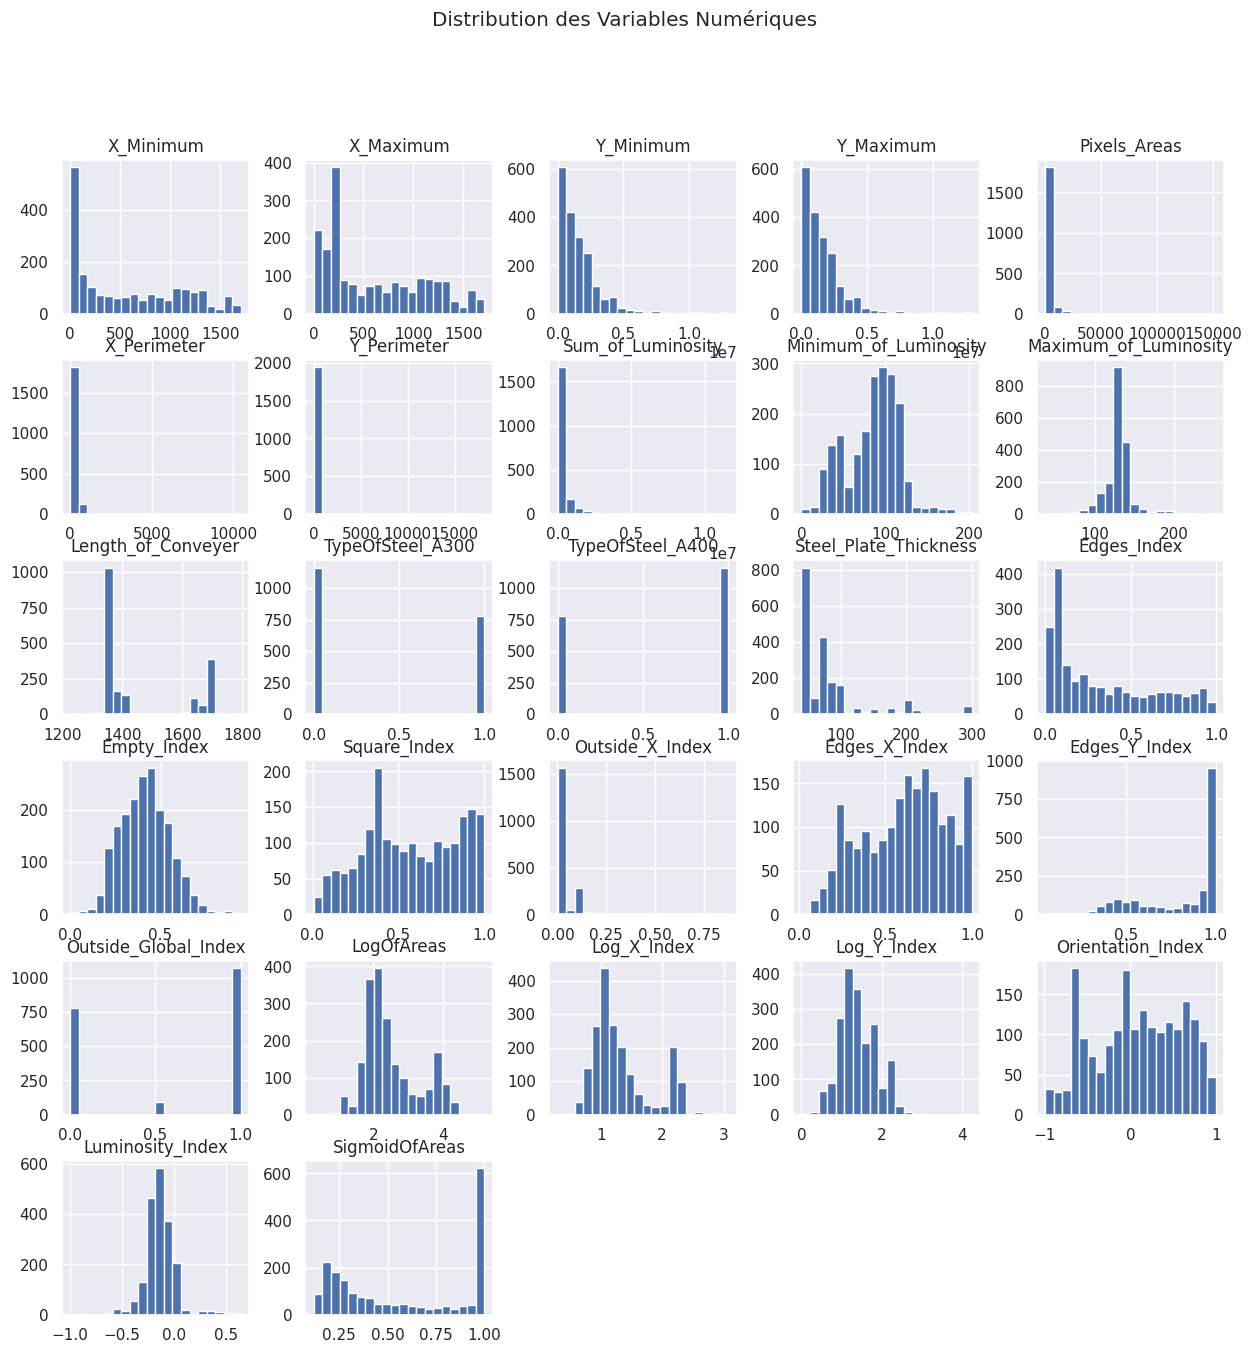

In [ ]:
# Histogrammes pour visualiser les distributions
data_cleaned[numerical_features].hist(bins=20, figsize=(15, 15))
plt.suptitle("Distribution des Variables Numériques")
plt.show()

## Distribution de la Variable Cible

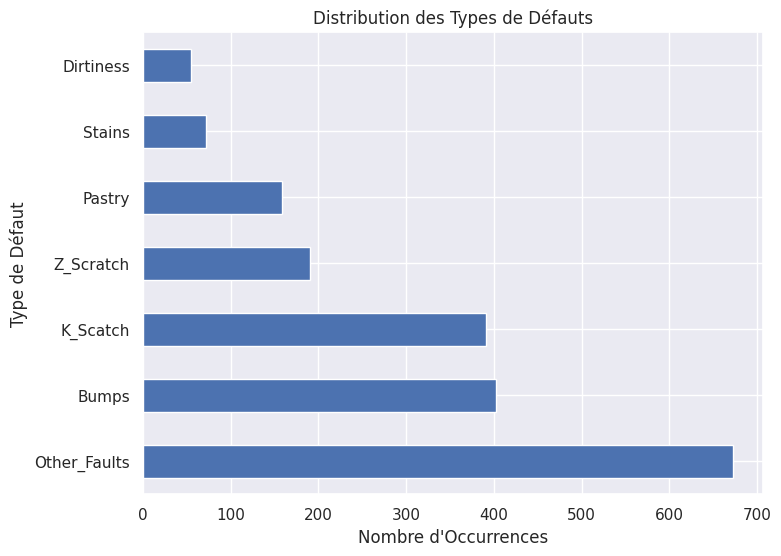

In [ ]:
# Distribution de la variable cible 'target'
plt.figure(figsize=(8, 6))
data_cleaned['target'].value_counts().plot(kind='barh')
plt.title("Distribution des Types de Défauts")
plt.xlabel("Nombre d'Occurrences")
plt.ylabel("Type de Défaut")
plt.show()

## Matrice de corrélation

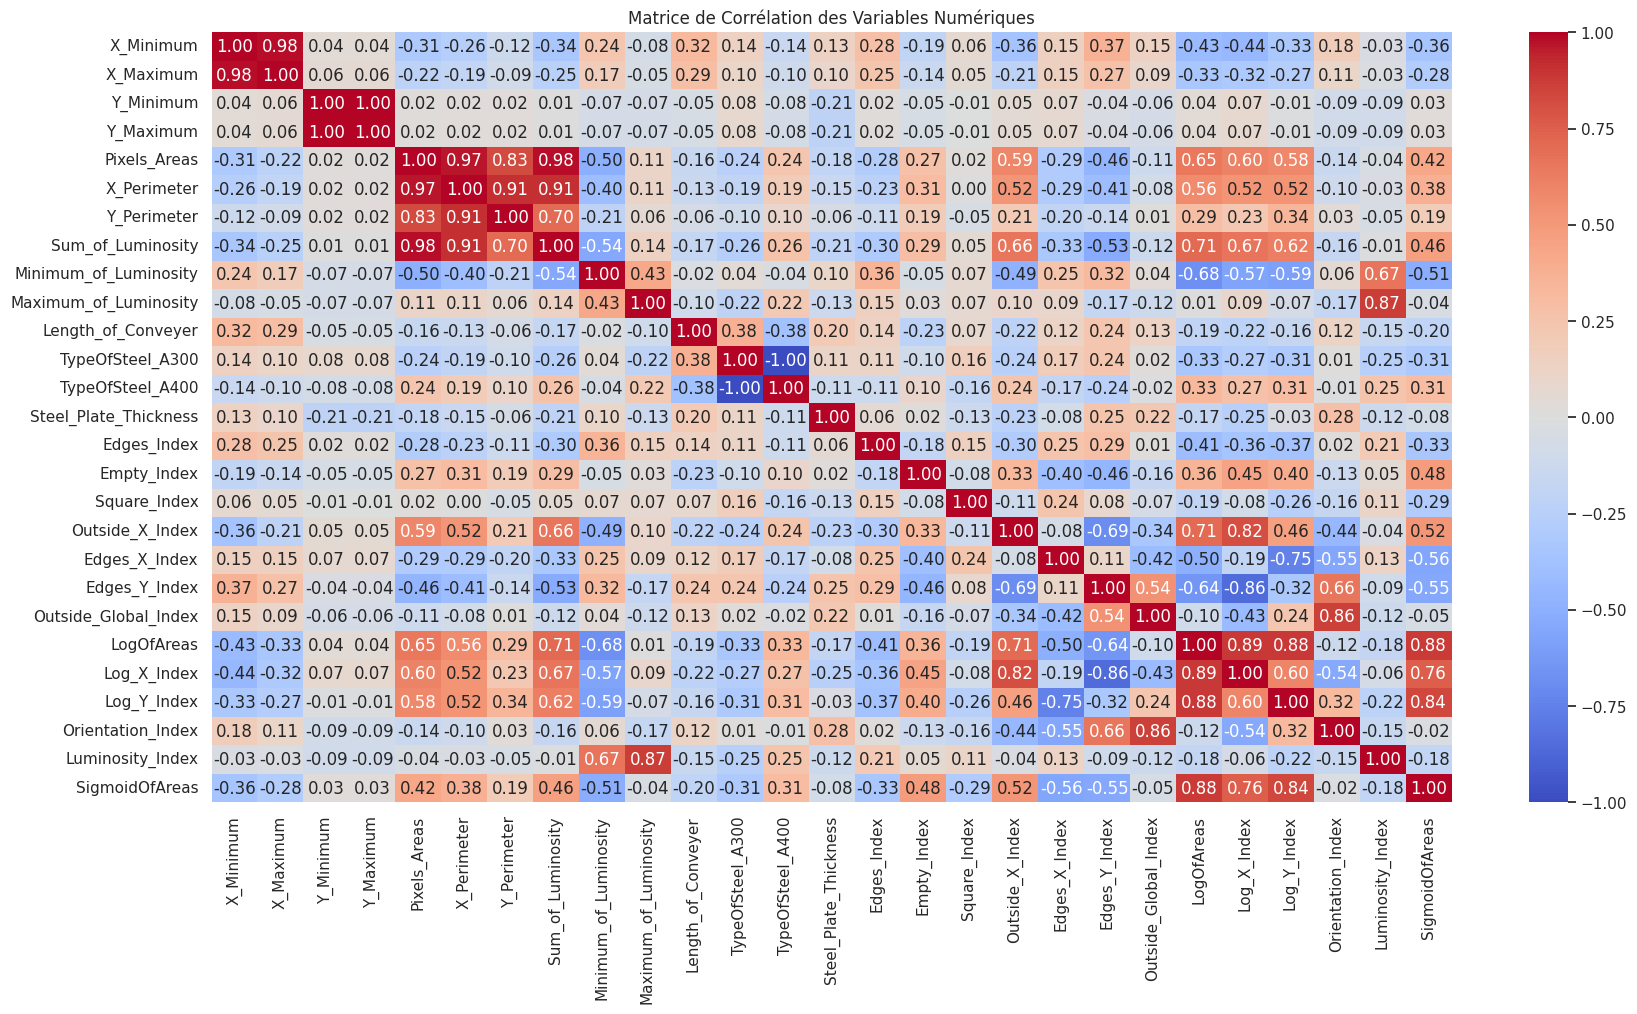

In [ ]:
plt.figure(figsize=(20, 10))
sns.heatmap(data_cleaned[numerical_features].corr(), annot=True, fmt=".2f", cmap="coolwarm", square=False)
plt.title("Matrice de Corrélation des Variables Numériques")
plt.show()

## Nuage de points


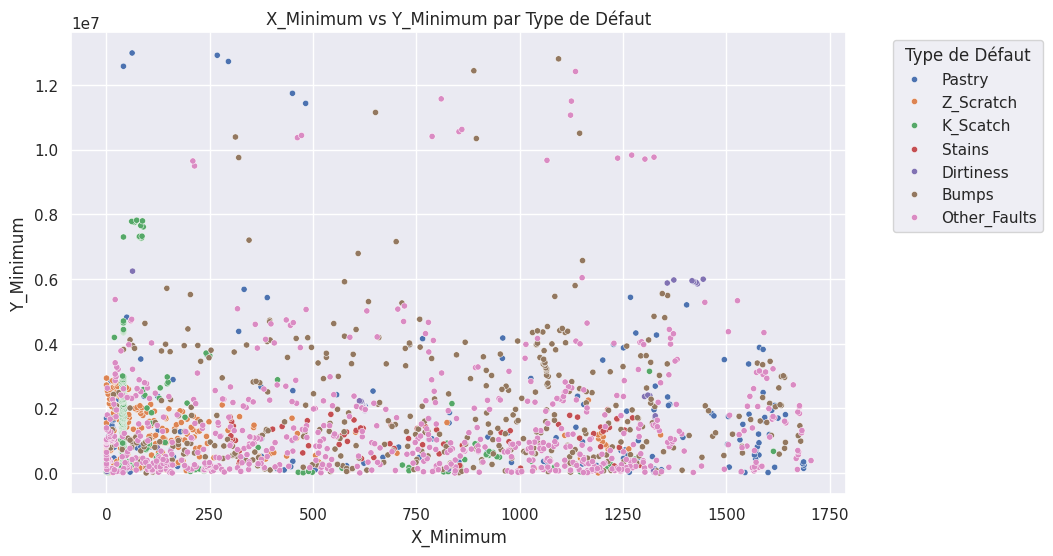

In [ ]:
# Nuage de points entre X_Minimum et Y_Minimum
plt.figure(figsize=(10, 6))
sns.scatterplot(x="X_Minimum", y="Y_Minimum", hue="target", data=data_cleaned, s=20)
plt.title("X_Minimum vs Y_Minimum par Type de Défaut")
plt.xlabel("X_Minimum")
plt.ylabel("Y_Minimum")
plt.legend(title="Type de Défaut", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

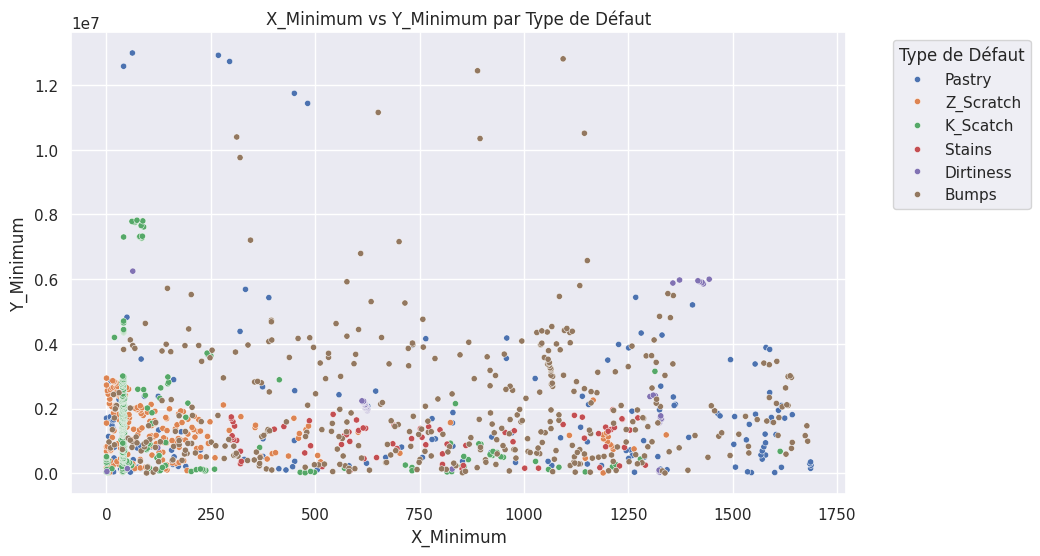

In [ ]:
# Filtrage des données pour exclure les valeurs "Other_Faults" dans la colonne target pour avoir une vue plus claire
data_filtered = data_cleaned[data_cleaned['target'] != 'Other_Faults']

# Création du nuage de points
plt.figure(figsize=(10, 6))
sns.scatterplot(x="X_Minimum", y="Y_Minimum", hue="target", data=data_filtered, s=20)
plt.title("X_Minimum vs Y_Minimum par Type de Défaut")
plt.xlabel("X_Minimum")
plt.ylabel("Y_Minimum")
plt.legend(title="Type de Défaut", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

## Boxplots par Feature

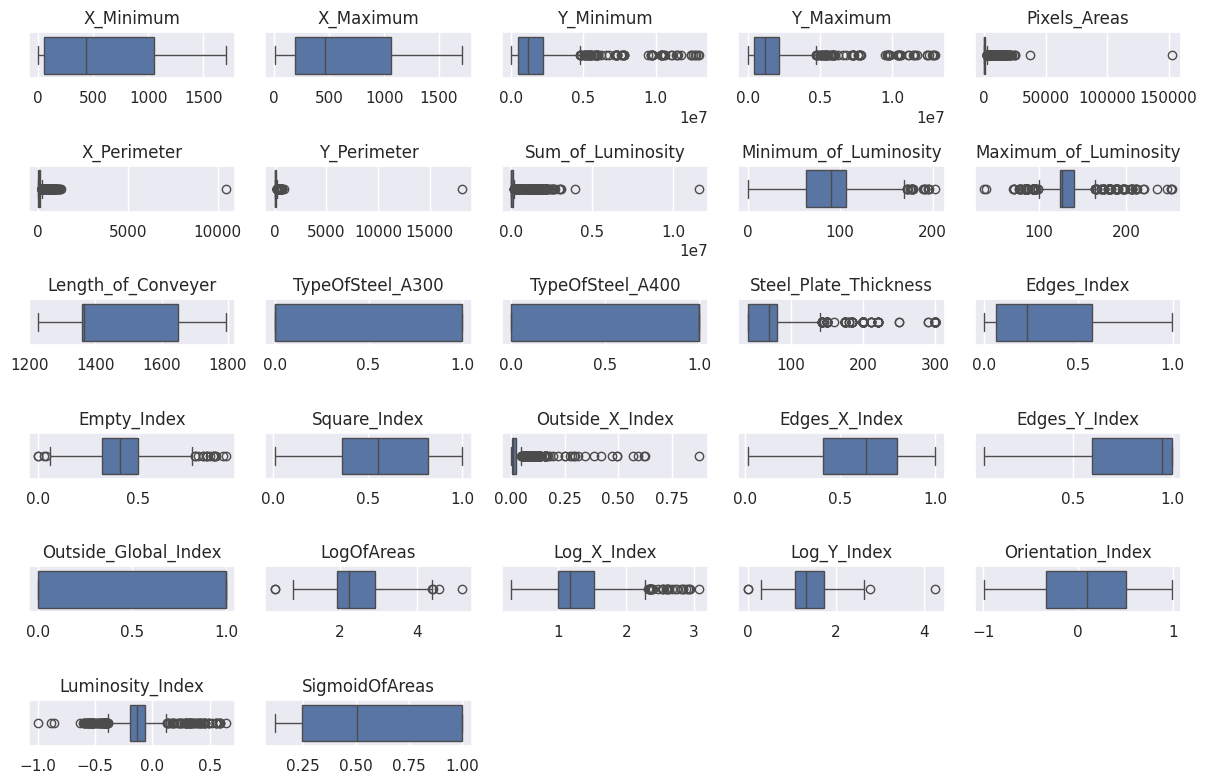

In [ ]:
# Dimensions de la figure globale
fig, axes = plt.subplots(nrows=6, ncols=5, figsize=(12, 8))
axes = axes.flatten()
# Afficher un boxplot pour chaque feature numérique dans la même figure
for i, col in enumerate(numerical_features):
    sns.boxplot(x=data_cleaned[col], ax=axes[i])
    axes[i].set_title(f"{col}")
    axes[i].set_xlabel("")  # Supprime l'étiquette de l'axe x en bas
# Supprimer les sous-figures inutilisées si nécessaire
for i in range(len(numerical_features), len(axes)):
    fig.delaxes(axes[i])
# Ajuster la disposition
plt.tight_layout()
plt.show()



## Boxplots par Classe Cible



In [ ]:
# Définir le nombre de lignes en fonction du nombre de features, avec une seule colonne
nrows = len(numerical_features)
ncols = 1
# Créer la figure globale avec une taille ajustée pour un espacement vertical plus large
fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(12, 4 * nrows))  # Augmenter la taille verticale
# Si `axes` est un tableau unidimensionnel (pour ncols=1), il n'est pas nécessaire de le "flatten"
# Afficher un boxplot pour chaque feature numérique par classe cible
for i, col in enumerate(numerical_features):
    sns.boxplot(x='target', y=col, data=data_cleaned, ax=axes[i])
    axes[i].set_title(f"Boxplot de {col} par Type de Défaut")
    axes[i].set_xlabel("Type de Défaut")
    axes[i].set_ylabel(col)
    axes[i].tick_params(axis='x', rotation=45)  # Rotation des étiquettes en bas
# Ajuster la disposition
plt.tight_layout()
plt.show()


# Préparation des Données

In [ ]:
"""# Conversion en DataFrame si nécessaire (si data_cleaned est un DataFrame, ce n'est pas nécessaire)
if not isinstance(data_cleaned, pd.DataFrame):
    data_cleaned = pd.DataFrame(data_cleaned, columns=[f'feature_{i}' for i in range(data_cleaned.shape[1]-1)] + ['target'])"""

"# Conversion en DataFrame si nécessaire (si data_cleaned est un DataFrame, ce n'est pas nécessaire)\nif not isinstance(data_cleaned, pd.DataFrame):\n    data_cleaned = pd.DataFrame(data_cleaned, columns=[f'feature_{i}' for i in range(data_cleaned.shape[1]-1)] + ['target'])"

## Encodage de la variable cible

In [ ]:
# Encodage de 'target' en numérique
label_encoder = LabelEncoder()
data_cleaned['target_encoded'] = label_encoder.fit_transform(data_cleaned['target'])

# Sélection et réduction des varibales

## Suppression des variables fortement corrélées

In [ ]:
# Suppression des variables redondantes
correlated_features = ['X_Maximum', 'Y_Maximum', 'Pixels_Areas', 'X_Perimeter',
                       'Sum_of_Luminosity', 'LogOfAreas', 'Log_Y_Index', 'TypeOfSteel_A400']
# , 'TypeOfSteel_A400'
data_reduced = data_cleaned.drop(columns=correlated_features)

## Réaffichage de la matrice de corrélation

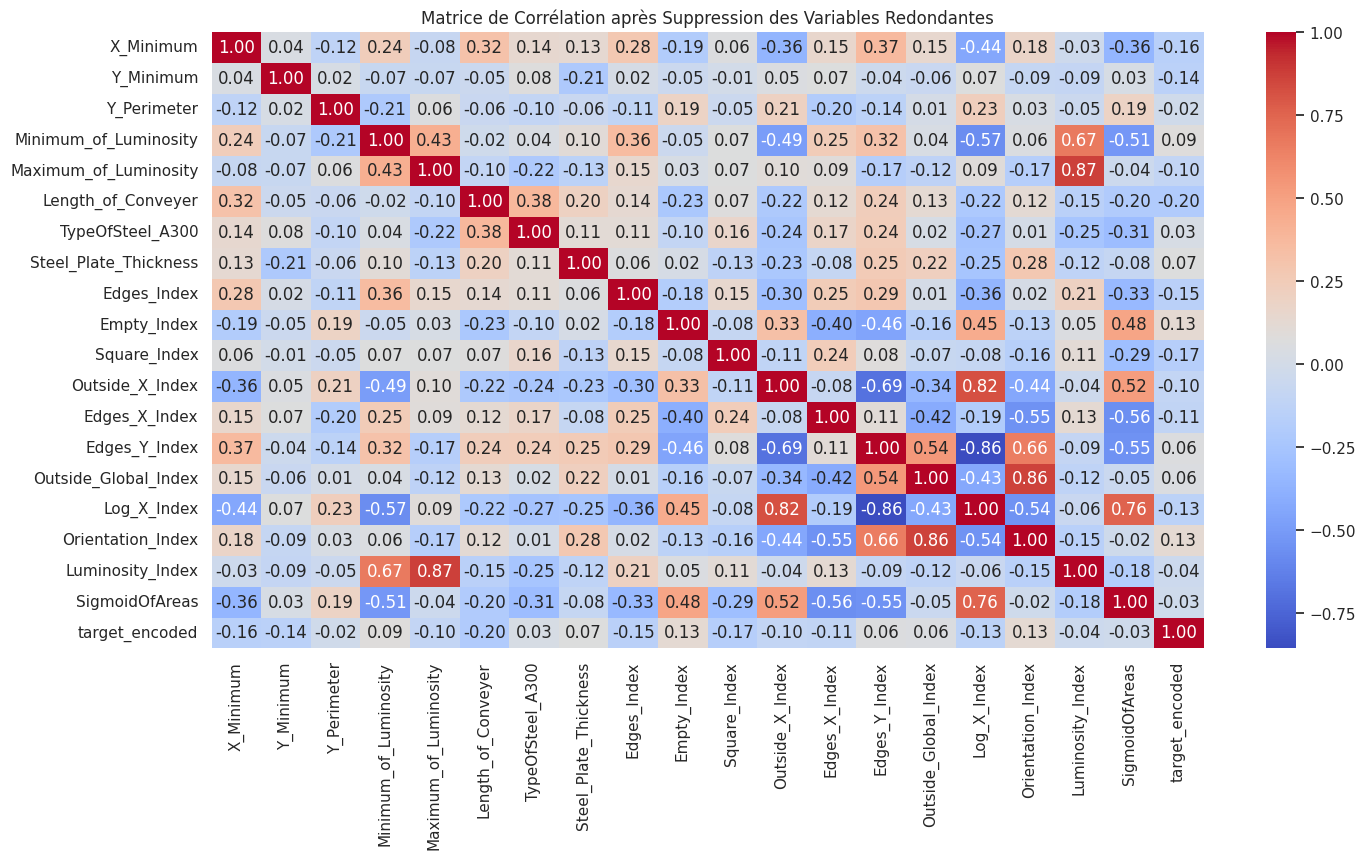

In [ ]:
# Mise à jour de la liste des variables numériques après suppression des variables corrélées
numerical_features_reduced = data_reduced.select_dtypes(include=[np.number]).columns.tolist()
# Matrice de corrélation après suppression des variables redondantes
plt.figure(figsize=(16, 8))
sns.heatmap(data_reduced[numerical_features_reduced].corr(), annot=True, fmt=".2f", cmap="coolwarm", square=False)
plt.title("Matrice de Corrélation après Suppression des Variables Redondantes")
plt.show()

## Réaffichage des valeurs numériques et textuelles

In [ ]:
# Liste des noms des colonnes des features numériques réduites
numerical_features_reduced = data_reduced.select_dtypes(include=[np.number]).columns.tolist()

# Affichage des noms des features dans une liste
print(len(numerical_features_reduced))

20


# Traitement des données

## Traitement des valeurs abérantes

In [ ]:
# Suppression des valeurs aberrantes
X = data_reduced.drop(columns=['target', 'target_encoded'])
y = data_reduced['target_encoded']
X_filtered = X.copy()
for col in X_filtered.columns:
    Q1 = X_filtered[col].quantile(0.25)
    Q3 = X_filtered[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    X_filtered = X_filtered[(X_filtered[col] >= lower_bound) & (X_filtered[col] <= upper_bound)]
# Synchronisation de y après suppression des valeurs aberrantes
indices_filtered = X_filtered.index
y_filtered = y.loc[indices_filtered].reset_index(drop=True)
X_filtered.reset_index(drop=True, inplace=True)

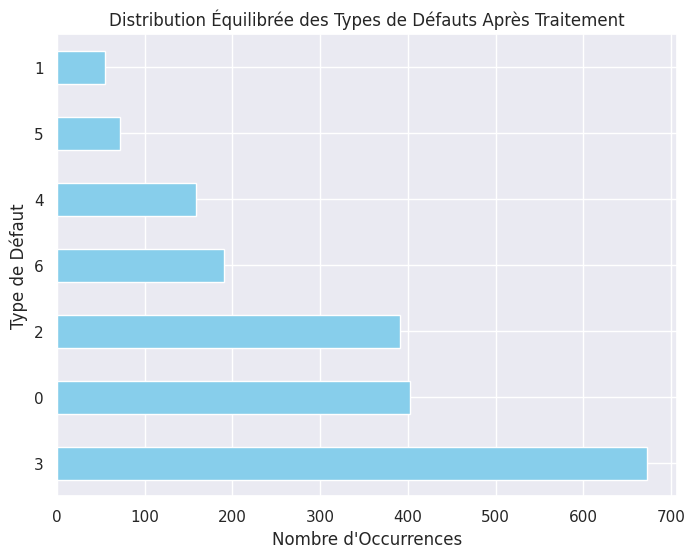

In [ ]:
# Nouvelle distribution de la variable cible après équilibrage et réduction de dimension
plt.figure(figsize=(8, 6))
y.value_counts().plot(kind='barh', color='skyblue')
plt.title("Distribution Équilibrée des Types de Défauts Après Traitement")
plt.xlabel("Nombre d'Occurrences")
plt.ylabel("Type de Défaut")
plt.show()

## Resampling (undersampling et oversampling pour atteindre 400 pour chaque target sauf le 3 (800))

In [ ]:
# Concaténation de X_filtered et y_filtered pour préparer l'équilibrage
data_filtered = X_filtered.copy()
data_filtered['target'] = y_filtered
# Rééquilibrage des classes après suppression des valeurs aberrantes
data_balanced = []
# Itération sur chaque classe pour ajuster le nombre d'échantillons
for class_label in data_filtered['target'].unique():
    data_class = data_filtered[data_filtered['target'] == class_label]
    if class_label == 3:
        # Pour la classe 3, augmenter davantage le nombre d'échantillons
        data_class_balanced = resample(data_class, replace=True, n_samples=800, random_state=42)
    elif len(data_class) < 400:
        # Pour les autres classes avec moins de 400 échantillons, utiliser un sur-échantillonnage
        data_class_balanced = resample(data_class, replace=True, n_samples=400, random_state=42)
    else:
        # Sinon, réaliser un sous-échantillonnage sans remplacement
        data_class_balanced = resample(data_class, replace=False, n_samples=400, random_state=42)
    data_balanced.append(data_class_balanced)
# Concaténation et mélange final des classes équilibrées
data_balanced = pd.concat(data_balanced).sample(frac=1, random_state=42).reset_index(drop=True)
# Séparation des features et de la target pour la suite du traitement
X_final = data_balanced.drop('target', axis=1)
y_final = data_balanced['target']

## Réduction de la dimensionalité avec PCA

In [ ]:
# Réduction de dimensionnalité avec PCA
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_final)
pca = PCA(n_components=0.95)  # Conserve 95% de la variance
X_pca = pca.fit_transform(X_scaled)
X_final_pca = pd.DataFrame(X_pca)

## Nouvelle distribution de la data

On choisit d'augmenter davantage les apparitions du la classe 3 pour permettre aux différents modèles d'apprendre suffisament à détecter efficacement cette classe, l'idée nous est venu après l'analyse des différentes matrices de confusion des modèles en fin de notebook

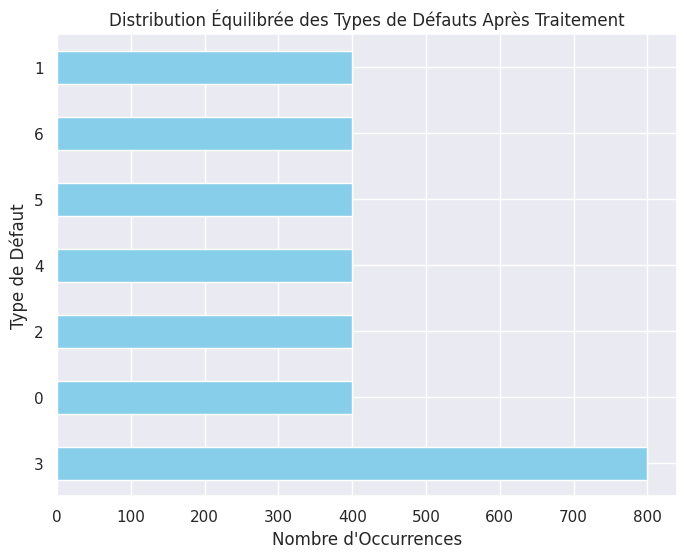

In [ ]:
# Nouvelle distribution de la variable cible après équilibrage et réduction de dimension
plt.figure(figsize=(8, 6))
y_final.value_counts().plot(kind='barh', color='skyblue')
plt.title("Distribution Équilibrée des Types de Défauts Après Traitement")
plt.xlabel("Nombre d'Occurrences")
plt.ylabel("Type de Défaut")
plt.show()

## Séparation du dataset

In [ ]:
# Séparation en ensembles d'entraînement et de test
X_train, X_test, y_train, y_test = train_test_split(X_final_pca, y_final,
                                                    test_size=0.2,
                                                    random_state=42,
                                                    stratify=y_final)

# Entraînement et Évaluation des Modèles machine learning

## Modèle 1 : K-Nearest Neighbors (KNN)

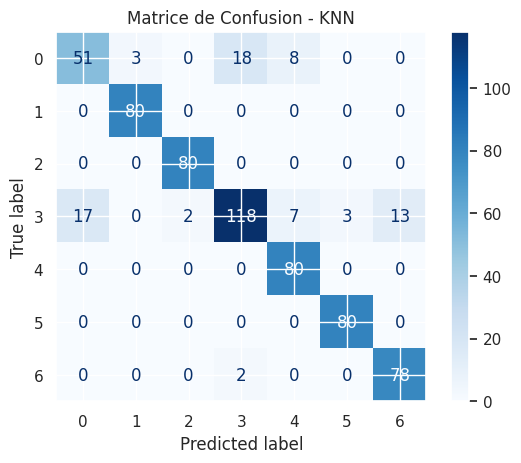



KNN - Rapport de Classification :

              precision    recall  f1-score   support

           0       0.75      0.64      0.69        80
           1       0.96      1.00      0.98        80
           2       0.98      1.00      0.99        80
           3       0.86      0.74      0.79       160
           4       0.84      1.00      0.91        80
           5       0.96      1.00      0.98        80
           6       0.86      0.97      0.91        80

    accuracy                           0.89       640
   macro avg       0.89      0.91      0.89       640
weighted avg       0.88      0.89      0.88       640





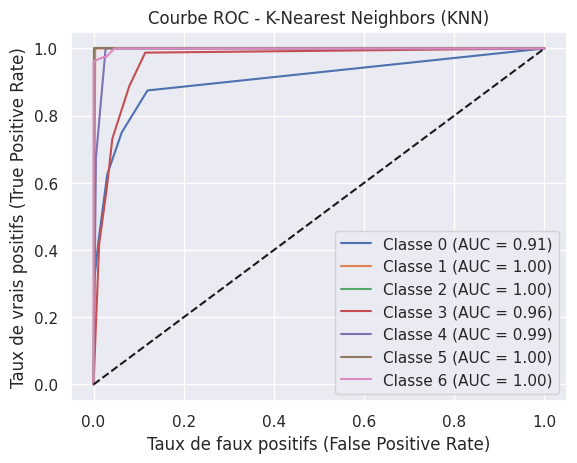

In [ ]:
# Entraînement du modèle KNN
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
# Prédictions et évaluation
y_pred_knn = knn.predict(X_test)
cm_knn = confusion_matrix(y_test, y_pred_knn)
ConfusionMatrixDisplay(cm_knn).plot(cmap="Blues")
plt.title("Matrice de Confusion - KNN")
plt.show()

print("\n" + "="*30 + "\n")

print("KNN - Rapport de Classification :\n")
print(classification_report(y_test, y_pred_knn))

print("\n" + "="*30 + "\n")

# Courbe ROC et AUC
y_test_bin = label_binarize(y_test, classes=np.unique(y))
y_pred_proba_knn = knn.predict_proba(X_test)
fpr = dict(); tpr = dict()
roc_auc = dict()
for i in range(y_test_bin.shape[1]):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_pred_proba_knn[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])
    plt.plot(fpr[i], tpr[i], label=f'Classe {i} (AUC = {roc_auc[i]:.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel("Taux de faux positifs (False Positive Rate)")
plt.ylabel("Taux de vrais positifs (True Positive Rate)")
plt.title("Courbe ROC - K-Nearest Neighbors (KNN)")
plt.legend()
plt.show()

## Modèle 2 : Support Vector Machine (SVM)

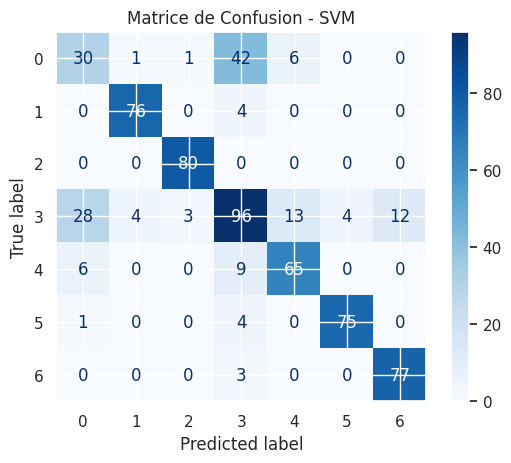



SVM - Rapport de Classification
              precision    recall  f1-score   support

           0       0.46      0.38      0.41        80
           1       0.94      0.95      0.94        80
           2       0.95      1.00      0.98        80
           3       0.61      0.60      0.60       160
           4       0.77      0.81      0.79        80
           5       0.95      0.94      0.94        80
           6       0.87      0.96      0.91        80

    accuracy                           0.78       640
   macro avg       0.79      0.81      0.80       640
weighted avg       0.77      0.78      0.77       640





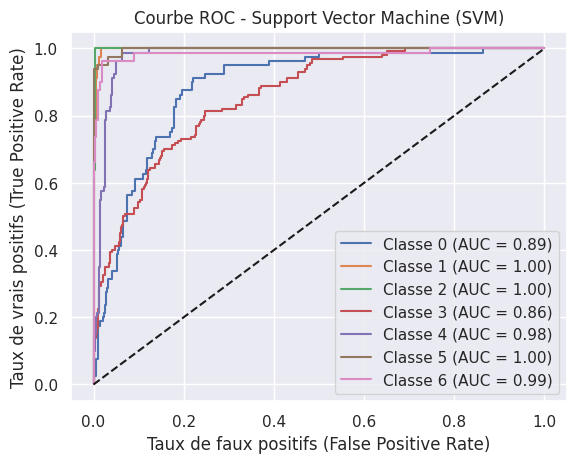

In [ ]:
# Entraînement du modèle SVM
svm = SVC(kernel='linear', decision_function_shape='ovr', probability=True)
svm.fit(X_train, y_train)
# Prédictions et évaluation
y_pred_svm = svm.predict(X_test)
cm_svm = confusion_matrix(y_test, y_pred_svm)
ConfusionMatrixDisplay(cm_svm).plot(cmap="Blues")
plt.title("Matrice de Confusion - SVM")
plt.show()

print("\n" + "="*40 + "\n")

print("SVM - Rapport de Classification")
print(classification_report(y_test, y_pred_svm))

print("\n" + "="*40 + "\n")

# Courbe ROC et AUC
y_pred_proba_svm = svm.predict_proba(X_test)
fpr, tpr, roc_auc = {}, {}, {}
for i in range(y_test_bin.shape[1]):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_pred_proba_svm[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])
    plt.plot(fpr[i], tpr[i], label=f'Classe {i} (AUC = {roc_auc[i]:.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel("Taux de faux positifs (False Positive Rate)")
plt.ylabel("Taux de vrais positifs (True Positive Rate)")
plt.title("Courbe ROC - Support Vector Machine (SVM)")
plt.legend()
plt.show()

## Modèle 3 : Decision Tree

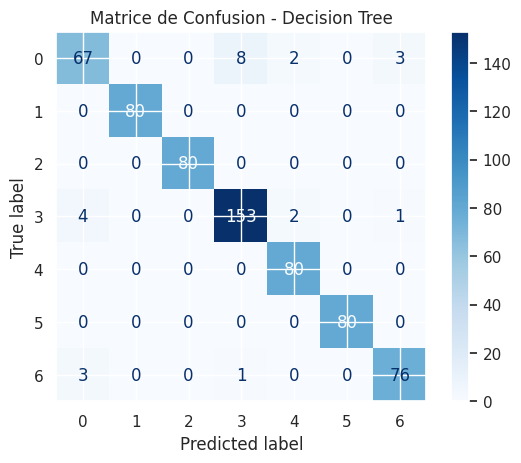



Decision Tree - Rapport de Classification
              precision    recall  f1-score   support

           0       0.91      0.84      0.87        80
           1       1.00      1.00      1.00        80
           2       1.00      1.00      1.00        80
           3       0.94      0.96      0.95       160
           4       0.95      1.00      0.98        80
           5       1.00      1.00      1.00        80
           6       0.95      0.95      0.95        80

    accuracy                           0.96       640
   macro avg       0.96      0.96      0.96       640
weighted avg       0.96      0.96      0.96       640





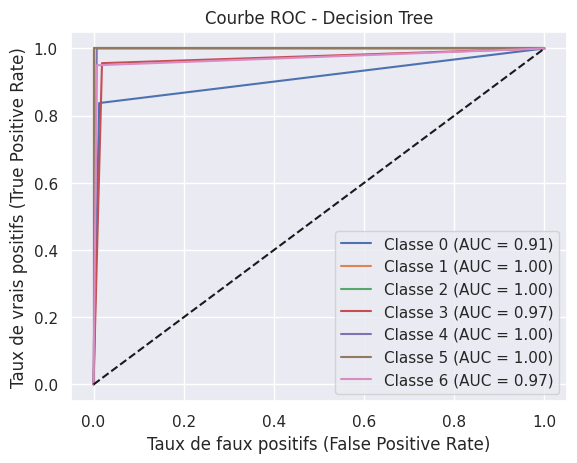

In [ ]:
# Entraînement du modèle Decision Tree
decision_tree = DecisionTreeClassifier(random_state=42)
decision_tree.fit(X_train, y_train)
# Prédictions et évaluation
y_pred_tree = decision_tree.predict(X_test)
cm_tree = confusion_matrix(y_test, y_pred_tree)
ConfusionMatrixDisplay(cm_tree).plot(cmap="Blues")
plt.title("Matrice de Confusion - Decision Tree")
plt.show()

print("\n" + "="*40 + "\n")

print("Decision Tree - Rapport de Classification")
print(classification_report(y_test, y_pred_tree))

print("\n" + "="*40 + "\n")

# Courbe ROC et AUC
y_pred_proba_tree = decision_tree.predict_proba(X_test)
fpr, tpr, roc_auc = {}, {}, {}
for i in range(y_test_bin.shape[1]):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_pred_proba_tree[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])
    plt.plot(fpr[i], tpr[i], label=f'Classe {i} (AUC = {roc_auc[i]:.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel("Taux de faux positifs (False Positive Rate)")
plt.ylabel("Taux de vrais positifs (True Positive Rate)")
plt.title("Courbe ROC - Decision Tree")
plt.legend()
plt.show()

## Modèle 4 : Random Forest

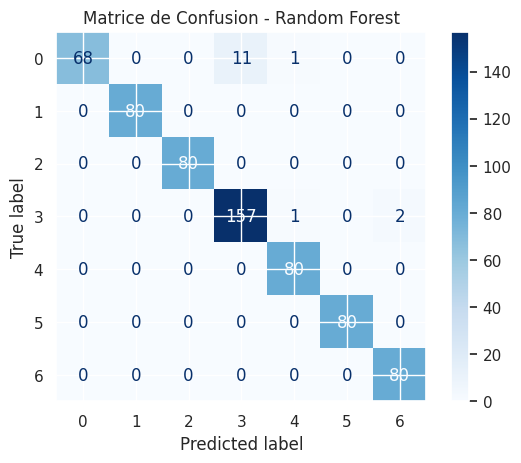



Random Forest - Rapport de Classification
              precision    recall  f1-score   support

           0       1.00      0.85      0.92        80
           1       1.00      1.00      1.00        80
           2       1.00      1.00      1.00        80
           3       0.93      0.98      0.96       160
           4       0.98      1.00      0.99        80
           5       1.00      1.00      1.00        80
           6       0.98      1.00      0.99        80

    accuracy                           0.98       640
   macro avg       0.98      0.98      0.98       640
weighted avg       0.98      0.98      0.98       640





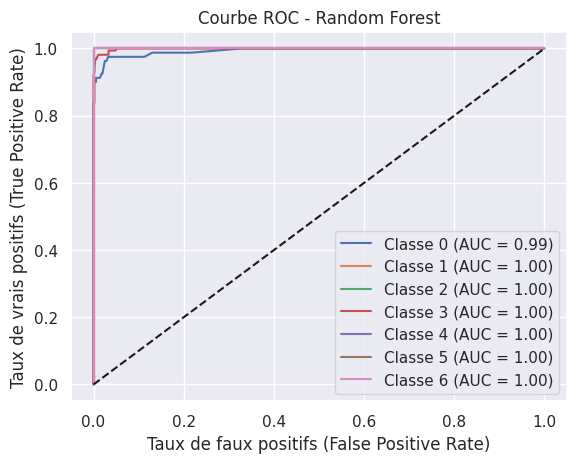

In [ ]:
# Entraînement du modèle Random Forest
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
# Prédictions et évaluation
y_pred_rf = rf.predict(X_test)
cm_rf = confusion_matrix(y_test, y_pred_rf)
ConfusionMatrixDisplay(cm_rf).plot(cmap="Blues")
plt.title("Matrice de Confusion - Random Forest")
plt.show()

print("\n" + "="*40 + "\n")

print("Random Forest - Rapport de Classification")
print(classification_report(y_test, y_pred_rf))

print("\n" + "="*40 + "\n")

# Courbe ROC et AUC
y_pred_proba_rf = rf.predict_proba(X_test)
fpr, tpr, roc_auc = {}, {}, {}
for i in range(y_test_bin.shape[1]):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_pred_proba_rf[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])
    plt.plot(fpr[i], tpr[i], label=f'Classe {i} (AUC = {roc_auc[i]:.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel("Taux de faux positifs (False Positive Rate)")
plt.ylabel("Taux de vrais positifs (True Positive Rate)")
plt.title("Courbe ROC - Random Forest")
plt.legend()
plt.show()

### Visualisation des Arbres de la Forêt

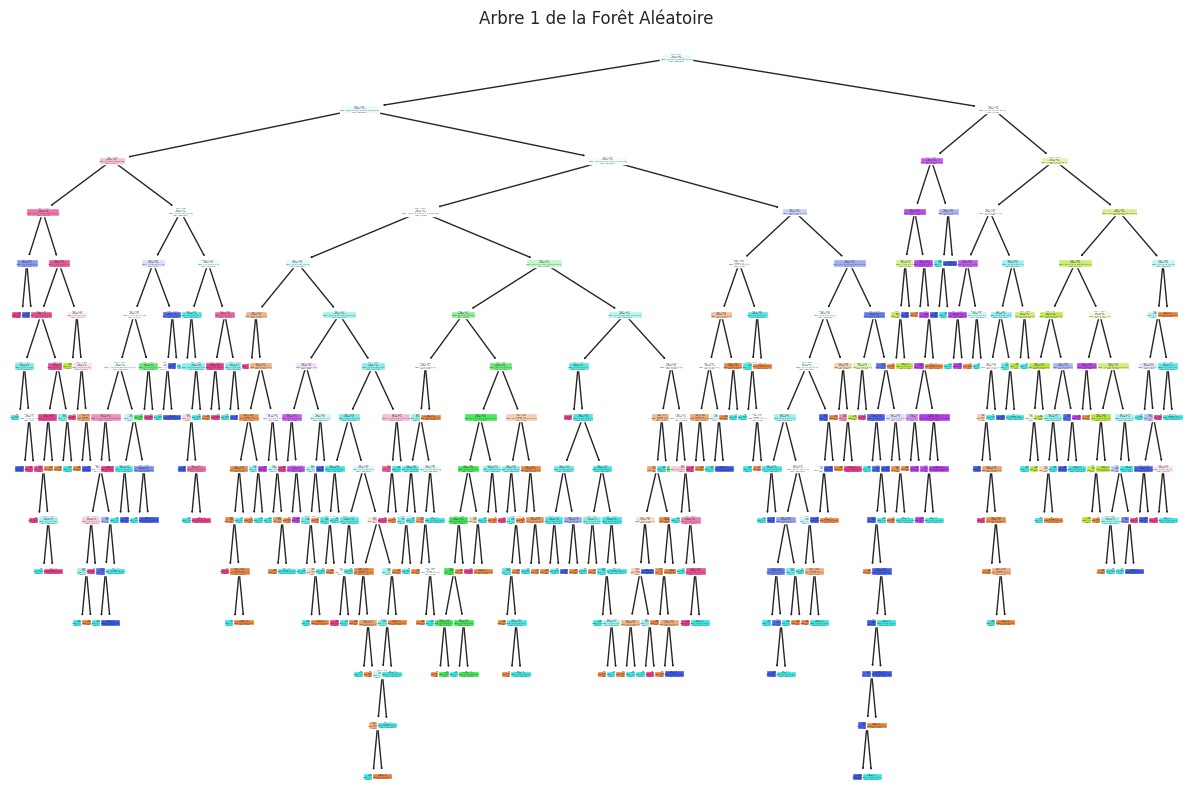

In [ ]:
# Visualisation des 2 premiers arbres de la forêt aléatoire
for i in range(1):
    plt.figure(figsize=(15, 10))
    plot_tree(rf.estimators_[i], filled=True,
              feature_names=[f'PC{i+1}' for i in range(X_train.shape[1])],
              class_names=label_encoder.classes_)
    plt.title(f"Arbre {i+1} de la Forêt Aléatoire")
    plt.show()

### Importance des Variables

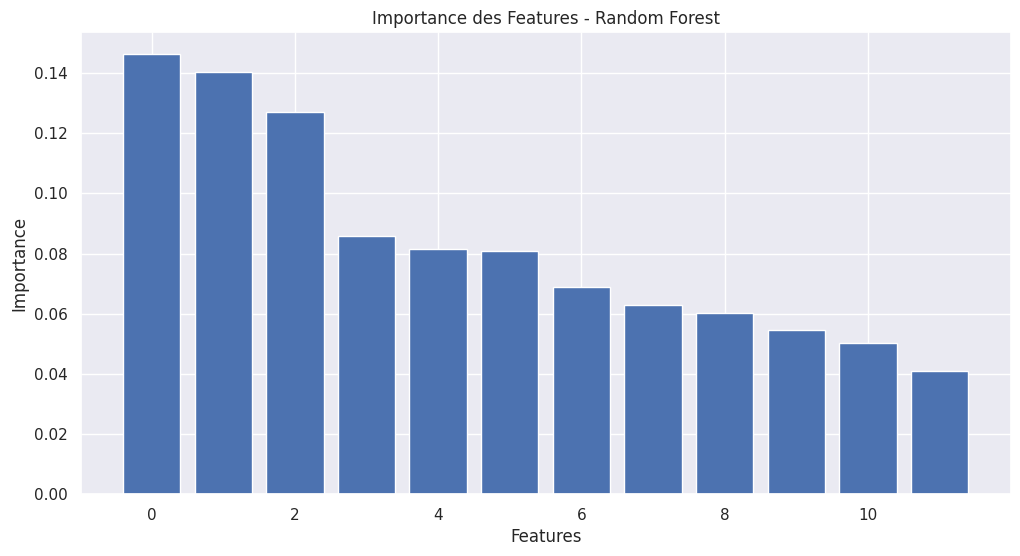

In [ ]:
# Importance des features
importances = rf.feature_importances_
indices = np.argsort(importances)[::-1]
# Tracé de l'importance des features
plt.figure(figsize=(12, 6))
plt.title("Importance des Features - Random Forest")
plt.bar(range(X_train.shape[1]), importances[indices], align='center')
plt.xlabel("Features")
plt.ylabel("Importance")
plt.show()

## Modèle 5 : XGBoost

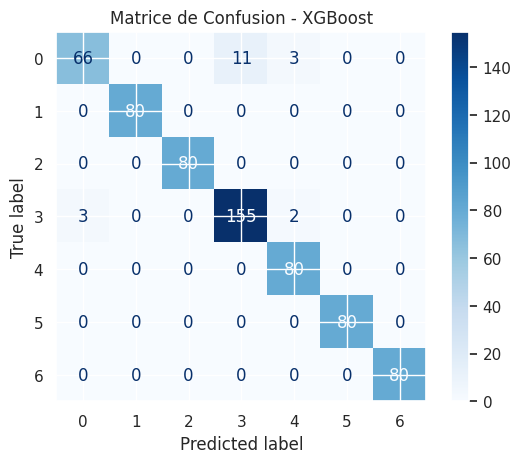



XGBoost - Rapport de Classification
              precision    recall  f1-score   support

           0       0.96      0.82      0.89        80
           1       1.00      1.00      1.00        80
           2       1.00      1.00      1.00        80
           3       0.93      0.97      0.95       160
           4       0.94      1.00      0.97        80
           5       1.00      1.00      1.00        80
           6       1.00      1.00      1.00        80

    accuracy                           0.97       640
   macro avg       0.98      0.97      0.97       640
weighted avg       0.97      0.97      0.97       640





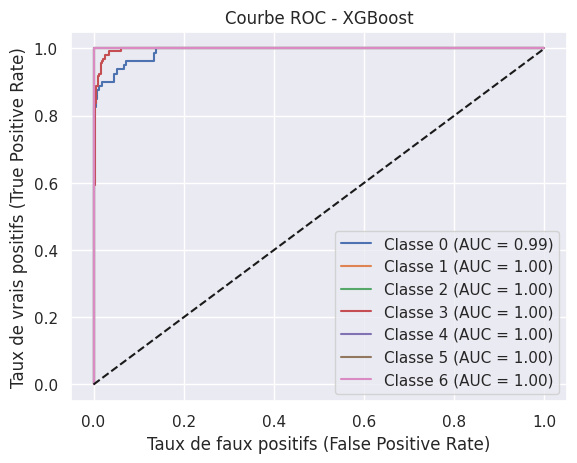

In [122]:
# Conversion des labels en format compatible (si nécessaire)
y_train_xgb = y_train
y_test_xgb = y_test

# Création des DMatrix pour XGBoost
dtrain = xgb.DMatrix(X_train, label=y_train_xgb)
dtest = xgb.DMatrix(X_test, label=y_test_xgb)

# Paramètres du modèle
params = {
    'objective': 'multi:softprob',
    'num_class': len(np.unique(y_train)),
    'eval_metric': 'mlogloss',
    'learning_rate': 0.1,
    'max_depth': 6,
    'seed': 42
}

# Liste des jeux de données pour l'évaluation
evals = [(dtrain, 'train'), (dtest, 'eval')]

# Entraînement du modèle avec suivi de l'évolution
num_round = 100  # Nombre d'itérations (époques)
evals_result = {}
bst = xgb.train(params, dtrain, num_round, evals=evals, evals_result=evals_result, verbose_eval=False)

# Prédictions
y_pred_proba = bst.predict(dtest)  # Prédictions probabilistes
y_pred = np.argmax(y_pred_proba, axis=1)  # Prédictions des classes

# Évaluation
cm_xgb = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm_xgb).plot(cmap="Blues")
plt.title("Matrice de Confusion - XGBoost")
plt.show()

print("\n" + "="*40 + "\n")

print("XGBoost - Rapport de Classification")
print(classification_report(y_test, y_pred))

print("\n" + "="*40 + "\n")

# Courbe ROC et AUC
from sklearn.preprocessing import label_binarize

classes = np.unique(y_test)
y_test_bin = label_binarize(y_test, classes=classes)

fpr, tpr, roc_auc = {}, {}, {}
for i in range(len(classes)):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_pred_proba[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])
    plt.plot(fpr[i], tpr[i], label=f'Classe {classes[i]} (AUC = {roc_auc[i]:.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel("Taux de faux positifs (False Positive Rate)")
plt.ylabel("Taux de vrais positifs (True Positive Rate)")
plt.title("Courbe ROC - XGBoost")
plt.legend()
plt.show()



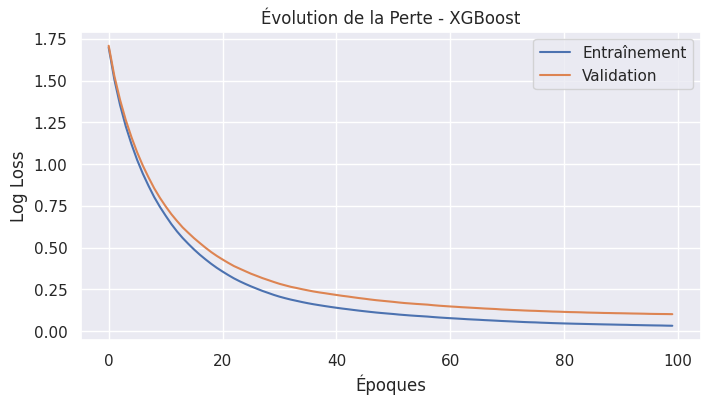

In [123]:
# Récupération des résultats
epochs = len(evals_result['train']['mlogloss'])
x_axis = range(0, epochs)
# Tracé de la courbe de perte
plt.figure(figsize=(8, 4))
plt.plot(x_axis, evals_result['train']['mlogloss'], label='Entraînement')
plt.plot(x_axis, evals_result['eval']['mlogloss'], label='Validation')
plt.title('Évolution de la Perte - XGBoost')
plt.xlabel('Époques')
plt.ylabel('Log Loss')
plt.legend()
plt.show()

## Modèle 6 : Logistic Regression

/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


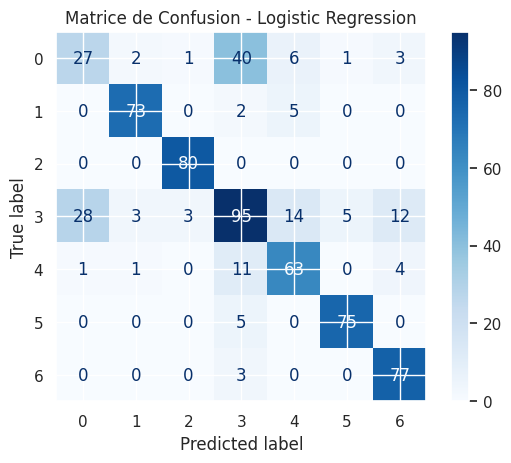



Logistic Regression - Rapport de Classification
              precision    recall  f1-score   support

           0       0.48      0.34      0.40        80
           1       0.92      0.91      0.92        80
           2       0.95      1.00      0.98        80
           3       0.61      0.59      0.60       160
           4       0.72      0.79      0.75        80
           5       0.93      0.94      0.93        80
           6       0.80      0.96      0.88        80

    accuracy                           0.77       640
   macro avg       0.77      0.79      0.78       640
weighted avg       0.75      0.77      0.76       640





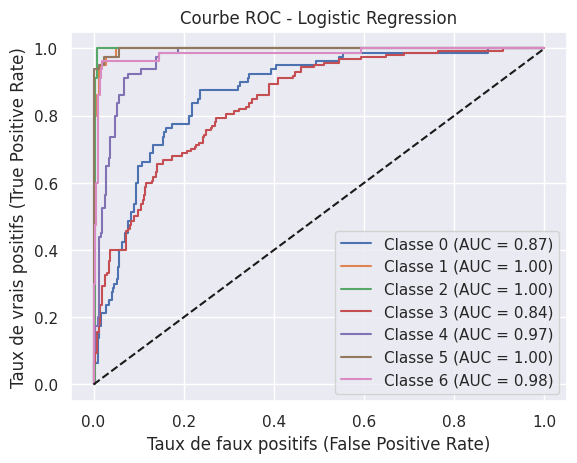

In [124]:
# Entraînement du modèle Logistic Regression
logreg = LogisticRegression(multi_class='multinomial', max_iter=1000, random_state=42)
logreg.fit(X_train, y_train)
# Prédictions et évaluation
y_pred_logreg = logreg.predict(X_test)
cm_logreg = confusion_matrix(y_test, y_pred_logreg)
ConfusionMatrixDisplay(cm_logreg).plot(cmap="Blues")
plt.title("Matrice de Confusion - Logistic Regression")
plt.show()

print("\n" + "="*40 + "\n")

print("Logistic Regression - Rapport de Classification")
print(classification_report(y_test, y_pred_logreg))

print("\n" + "="*40 + "\n")

# Courbe ROC et AUC
y_pred_proba_logreg = logreg.predict_proba(X_test)
fpr, tpr, roc_auc = {}, {}, {}
for i in range(y_test_bin.shape[1]):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_pred_proba_logreg[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])
    plt.plot(fpr[i], tpr[i], label=f'Classe {i} (AUC = {roc_auc[i]:.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel("Taux de faux positifs (False Positive Rate)")
plt.ylabel("Taux de vrais positifs (True Positive Rate)")
plt.title("Courbe ROC - Logistic Regression")
plt.legend()
plt.show()

## Modèle 7 : Naive Bayes

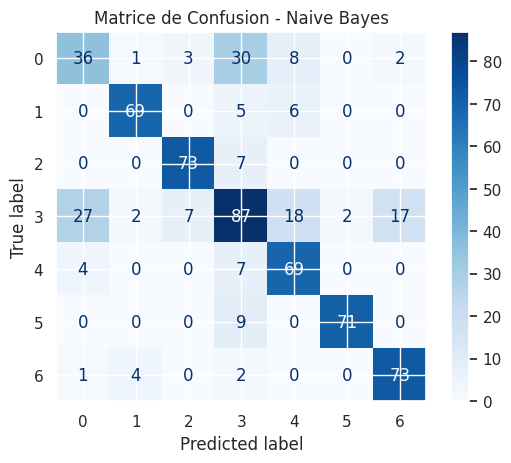



Naive Bayes - Rapport de Classification
              precision    recall  f1-score   support

           0       0.53      0.45      0.49        80
           1       0.91      0.86      0.88        80
           2       0.88      0.91      0.90        80
           3       0.59      0.54      0.57       160
           4       0.68      0.86      0.76        80
           5       0.97      0.89      0.93        80
           6       0.79      0.91      0.85        80

    accuracy                           0.75       640
   macro avg       0.77      0.78      0.77       640
weighted avg       0.74      0.75      0.74       640





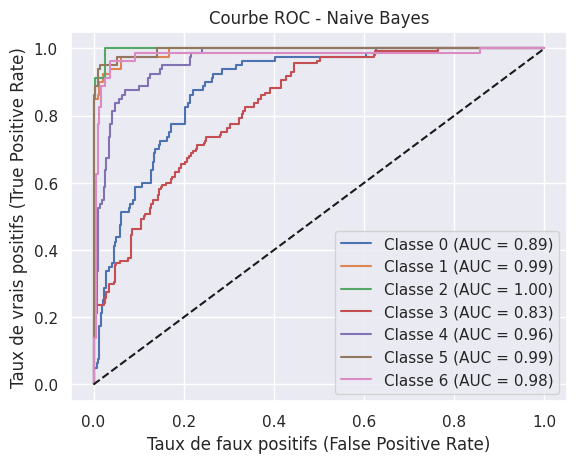

In [125]:
# Entraînement du modèle Naive Bayes
naive_bayes = GaussianNB()
naive_bayes.fit(X_train, y_train)
# Prédictions et évaluation
y_pred_nb = naive_bayes.predict(X_test)
cm_nb = confusion_matrix(y_test, y_pred_nb)
ConfusionMatrixDisplay(cm_nb).plot(cmap="Blues")
plt.title("Matrice de Confusion - Naive Bayes")
plt.show()

print("\n" + "="*40 + "\n")

print("Naive Bayes - Rapport de Classification")
print(classification_report(y_test, y_pred_nb))

print("\n" + "="*40 + "\n")

# Courbe ROC et AUC
y_pred_proba_nb = naive_bayes.predict_proba(X_test)
fpr, tpr, roc_auc = {}, {}, {}
for i in range(y_test_bin.shape[1]):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_pred_proba_nb[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])
    plt.plot(fpr[i], tpr[i], label=f'Classe {i} (AUC = {roc_auc[i]:.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel("Taux de faux positifs (False Positive Rate)")
plt.ylabel("Taux de vrais positifs (True Positive Rate)")
plt.title("Courbe ROC - Naive Bayes")
plt.legend()
plt.show()

# Modèle 8 : Artificial Neural Network (ANN)

## Définition et entraînement de l'ANN

In [126]:
# Définition du modèle ANN de base
model = Sequential()
model.add(Dense(64, activation='relu', input_shape=(X_train.shape[1],)))
model.add(Dropout(0.3))
model.add(Dense(32, activation='relu'))
model.add(Dropout(0.3))
model.add(Dense(16, activation='relu'))
model.add(Dense(len(np.unique(y_train)), activation='softmax'))  # Nombre de neurones de sortie = nombre de classes
# Compilation du modèle
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

/usr/local/lib/python3.10/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [127]:
# Entraînement du modèle
history_ann = model.fit(X_train, y_train, epochs=140, validation_data=(X_test, y_test), verbose=1)

Epoch 1/140
80/80 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.2667 - loss: 1.8597 - val_accuracy: 0.6047 - val_loss: 1.4095
Epoch 2/140
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.4863 - loss: 1.3948 - val_accuracy: 0.6812 - val_loss: 0.9237
Epoch 3/140
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.5964 - loss: 1.0459 - val_accuracy: 0.7078 - val_loss: 0.7580
Epoch 4/140
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.6320 - loss: 0.9284 - val_accuracy: 0.7422 - val_loss: 0.6773
Epoch 5/140
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.6732 - loss: 0.8761 - val_accuracy: 0.7547 - val_loss: 0.6258
Epoch 6/140
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.6986 - loss: 0.7727 - val_accuracy: 0.7781 - val_loss: 0.5952
Epoch 7/140
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7050 - loss: 0.7422 - val_accuracy: 0.7734 - val_loss: 0.5845
Epoch 8/140
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7236 - loss: 0.7203 - val_accuracy: 0.7734 - v

## Évaluation du modèle

20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


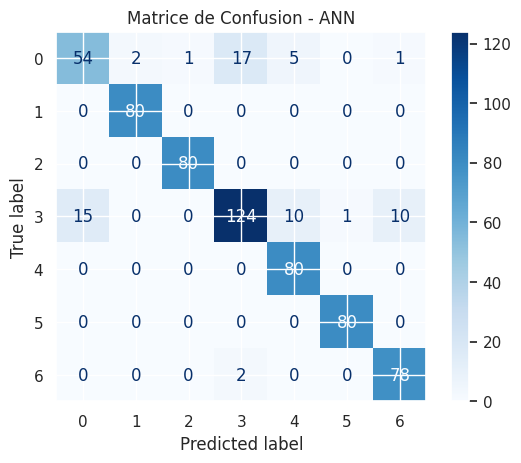

ANN - Rapport de Classification
              precision    recall  f1-score   support

           0       0.78      0.68      0.72        80
           1       0.98      1.00      0.99        80
           2       0.99      1.00      0.99        80
           3       0.87      0.78      0.82       160
           4       0.84      1.00      0.91        80
           5       0.99      1.00      0.99        80
           6       0.88      0.97      0.92        80

    accuracy                           0.90       640
   macro avg       0.90      0.92      0.91       640
weighted avg       0.90      0.90      0.90       640



In [128]:
# Prédictions sur le jeu de test
y_pred_ann = model.predict(X_test)
y_pred_labels_ann = np.argmax(y_pred_ann, axis=1)
# Matrice de confusion
cm_ann = confusion_matrix(y_test, y_pred_labels_ann)
ConfusionMatrixDisplay(cm_ann).plot(cmap="Blues")
plt.title("Matrice de Confusion - ANN")
plt.show()
# Rapport de classification
print("ANN - Rapport de Classification")
print(classification_report(y_test, y_pred_labels_ann))

## Affichage des Courbes d'Entraînement (Accuracy et Loss)

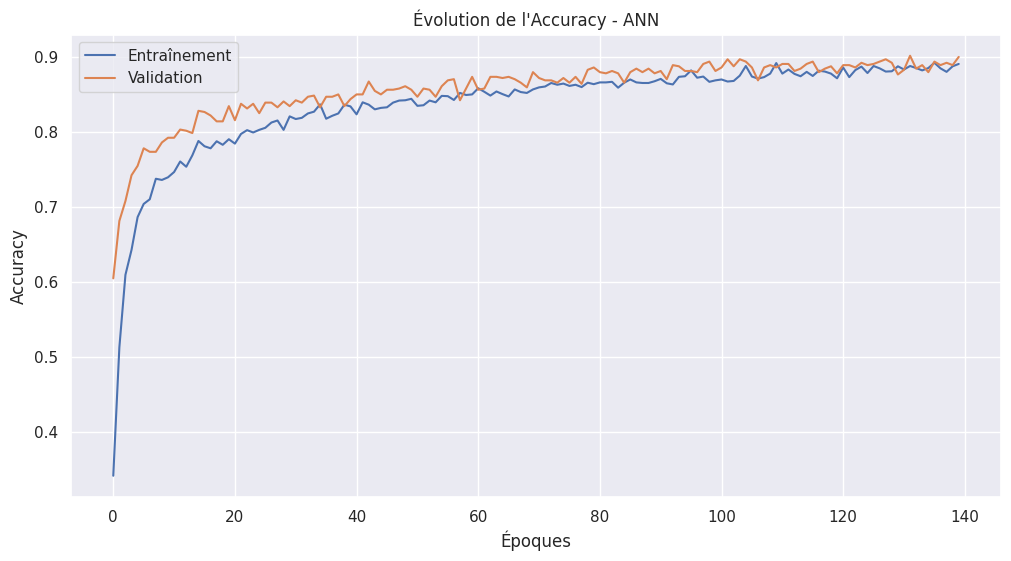

In [129]:
# Évolution de l'Accuracy
plt.figure(figsize=(12, 6))
plt.plot(history_ann.history['accuracy'], label='Entraînement')
plt.plot(history_ann.history['val_accuracy'], label='Validation')
plt.title("Évolution de l'Accuracy - ANN")
plt.xlabel("Époques")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

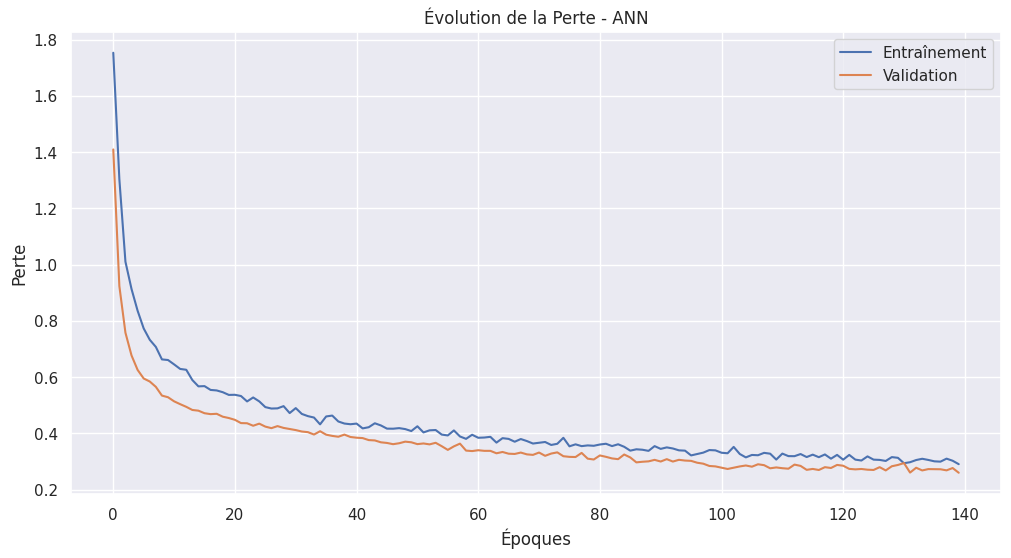

In [130]:
# Évolution de la Perte
plt.figure(figsize=(12, 6))
plt.plot(history_ann.history['loss'], label='Entraînement')
plt.plot(history_ann.history['val_loss'], label='Validation')
plt.title("Évolution de la Perte - ANN")
plt.xlabel("Époques")
plt.ylabel("Perte")
plt.legend()
plt.show()

## Courbe ROC Pour le ANN

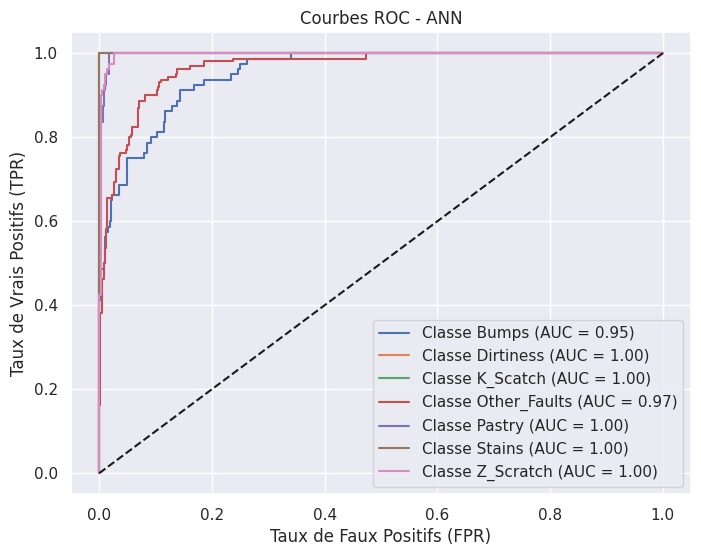

In [131]:
# Binarisation des labels pour la courbe ROC
y_test_bin = label_binarize(y_test, classes=np.unique(y_test))
n_classes = y_test_bin.shape[1]
# Calcul des courbes ROC et de l'AUC pour chaque classe
fpr = dict()
tpr = dict()
roc_auc = dict()
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_pred_ann[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])
# Tracé des courbes ROC pour chaque classe
plt.figure(figsize=(8, 6))
for i in range(n_classes):
    plt.plot(fpr[i], tpr[i], label=f"Classe {label_encoder.inverse_transform([i])[0]} (AUC = {roc_auc[i]:.2f})")
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel("Taux de Faux Positifs (FPR)")
plt.ylabel("Taux de Vrais Positifs (TPR)")
plt.title("Courbes ROC - ANN")
plt.legend(loc='lower right')
plt.show()

# Optimisation du Modèle ANN avec Keras Tuner

In [132]:
# Fonction pour créer le modèle
def build_model(hp):
    model = Sequential()
    for i in range(hp.Int('num_layers', 2, 5)):
        units = hp.Int(f'units_{i}', min_value=64, max_value=256, step=64)
        activation_choice = hp.Choice('activation', ['relu', 'leaky_relu', 'elu'])
        if activation_choice == 'leaky_relu':
            model.add(Dense(units))
            model.add(LeakyReLU())
        elif activation_choice == 'elu':
            model.add(Dense(units))
            model.add(ELU())
        else:
            model.add(Dense(units, activation='relu'))
        dropout_rate = hp.Float(f'dropout_{i}', 0.2, 0.5, step=0.1)
        model.add(Dropout(rate=dropout_rate))
    model.add(Dense(len(np.unique(y_train)), activation='softmax'))
    learning_rate = hp.Choice('learning_rate', [1e-2, 1e-3, 1e-4])
    model.compile(optimizer=Adam(learning_rate=learning_rate),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model
# Configuration du tuner
tuner = kt.Hyperband(build_model, objective='val_accuracy', max_epochs=50,
                     factor=3, directory='my_dir',
                     project_name='ANN_hyperparameter_tuning')
# Recherche des meilleurs hyperparamètres
tuner.search(X_train, y_train, epochs=50, validation_data=(X_test, y_test), verbose=1)

Trial 90 Complete [00h 00m 23s]
val_accuracy: 0.7875000238418579

Best val_accuracy So Far: 0.96875
Total elapsed time: 00h 14m 30s


## Affichage des meilleurs hyperparamètres

In [133]:
# Récupération des meilleurs hyperparamètres
best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]
print("Meilleurs hyperparamètres trouvés :")
print(f"Nombre optimal de couches cachées : {best_hps.get('num_layers')}")
for i in range(best_hps.get('num_layers')):
    units = best_hps.get(f'units_{i}')
    activation = best_hps.get('activation')
    dropout = best_hps.get(f'dropout_{i}')
    print(f"Couche {i+1} - Neurones : {units}, Activation : {activation}, Dropout : {dropout}")
print(f"Taux d'apprentissage optimal : {best_hps.get('learning_rate')}")

Meilleurs hyperparamètres trouvés :
Nombre optimal de couches cachées : 3
Couche 1 - Neurones : 128, Activation : relu, Dropout : 0.2
Couche 2 - Neurones : 256, Activation : relu, Dropout : 0.2
Couche 3 - Neurones : 128, Activation : relu, Dropout : 0.4
Taux d'apprentissage optimal : 0.001


## Entrainement du meilleur modèle et visualisation

In [134]:
  # Construction du modèle avec les meilleurs hyperparamètres
best_model = tuner.hypermodel.build(best_hps)
# Entraînement du modèle
history = best_model.fit(X_train, y_train, epochs=120, batch_size=32, validation_data=(X_test, y_test), verbose=1)

Epoch 1/120
80/80 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.4424 - loss: 1.4607 - val_accuracy: 0.7359 - val_loss: 0.6425
Epoch 2/120
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7192 - loss: 0.7020 - val_accuracy: 0.7891 - val_loss: 0.5309
Epoch 3/120
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7729 - loss: 0.5974 - val_accuracy: 0.8172 - val_loss: 0.4685
Epoch 4/120
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7995 - loss: 0.5486 - val_accuracy: 0.8313 - val_loss: 0.4306
Epoch 5/120
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8198 - loss: 0.4836 - val_accuracy: 0.8469 - val_loss: 0.4120
Epoch 6/120
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8250 - loss: 0.4503 - val_accuracy: 0.8438 - val_loss: 0.3944
Epoch 7/120
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8579 - loss: 0.4060 - val_accuracy: 0.8578 - val_loss: 0.3622
Epoch 8/120
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8578 - loss: 0.3716 - val_accuracy: 0.8750 - v

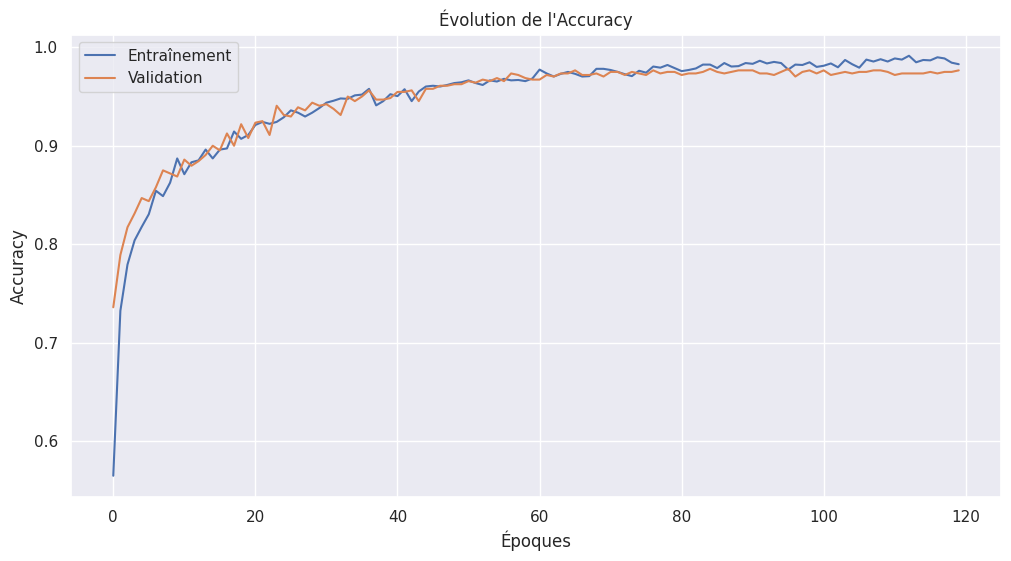

In [135]:
# Évolution de l'Accuracy
plt.figure(figsize=(12, 6))
plt.plot(history.history['accuracy'], label='Entraînement')
plt.plot(history.history['val_accuracy'], label='Validation')
plt.title("Évolution de l'Accuracy")
plt.xlabel("Époques")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

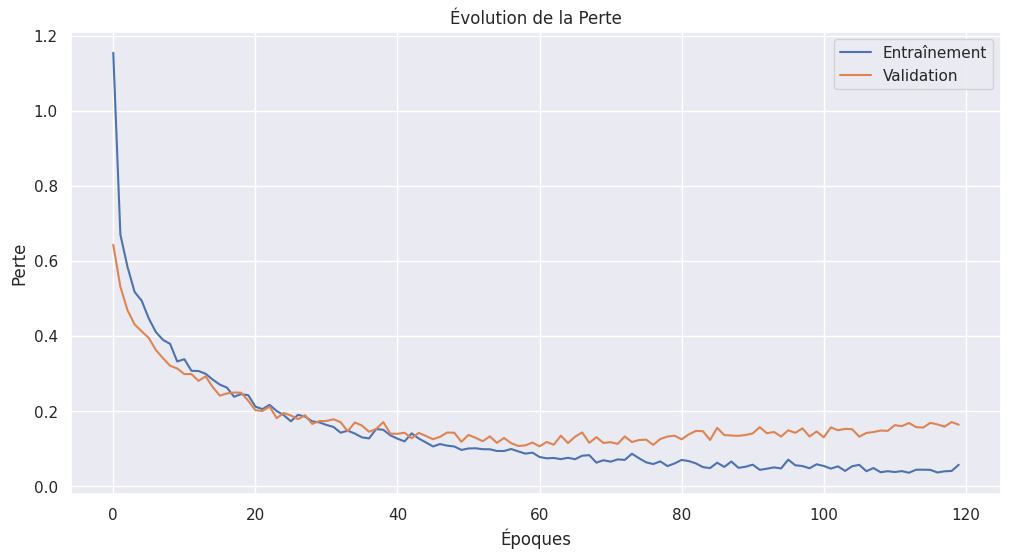

In [136]:
# Évolution de la Perte
plt.figure(figsize=(12, 6))
plt.plot(history.history['loss'], label='Entraînement')
plt.plot(history.history['val_loss'], label='Validation')
plt.title("Évolution de la Perte")
plt.xlabel("Époques")
plt.ylabel("Perte")
plt.legend()
plt.show()

## Évaluation du modèle optimisé

20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


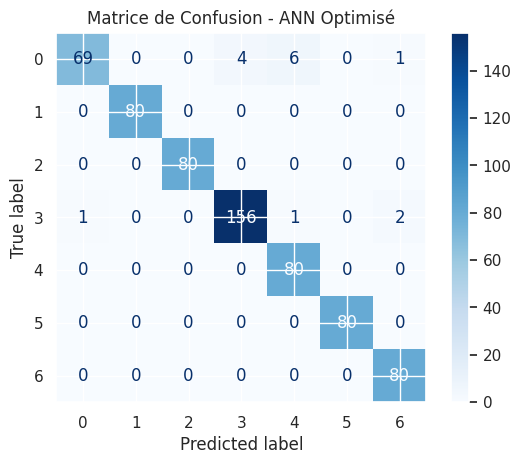

ANN Optimisé - Rapport de Classification
              precision    recall  f1-score   support

           0       0.99      0.86      0.92        80
           1       1.00      1.00      1.00        80
           2       1.00      1.00      1.00        80
           3       0.97      0.97      0.97       160
           4       0.92      1.00      0.96        80
           5       1.00      1.00      1.00        80
           6       0.96      1.00      0.98        80

    accuracy                           0.98       640
   macro avg       0.98      0.98      0.98       640
weighted avg       0.98      0.98      0.98       640



In [137]:
# Prédictions sur le jeu de test
y_pred_ann = best_model.predict(X_test)
y_pred_labels_ann = np.argmax(y_pred_ann, axis=1)
# Matrice de confusion
cm_ann = confusion_matrix(y_test, y_pred_labels_ann)
ConfusionMatrixDisplay(cm_ann).plot(cmap="Blues")
plt.title("Matrice de Confusion - ANN Optimisé")
plt.show()
print("ANN Optimisé - Rapport de Classification")
print(classification_report(y_test, y_pred_labels_ann))

20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


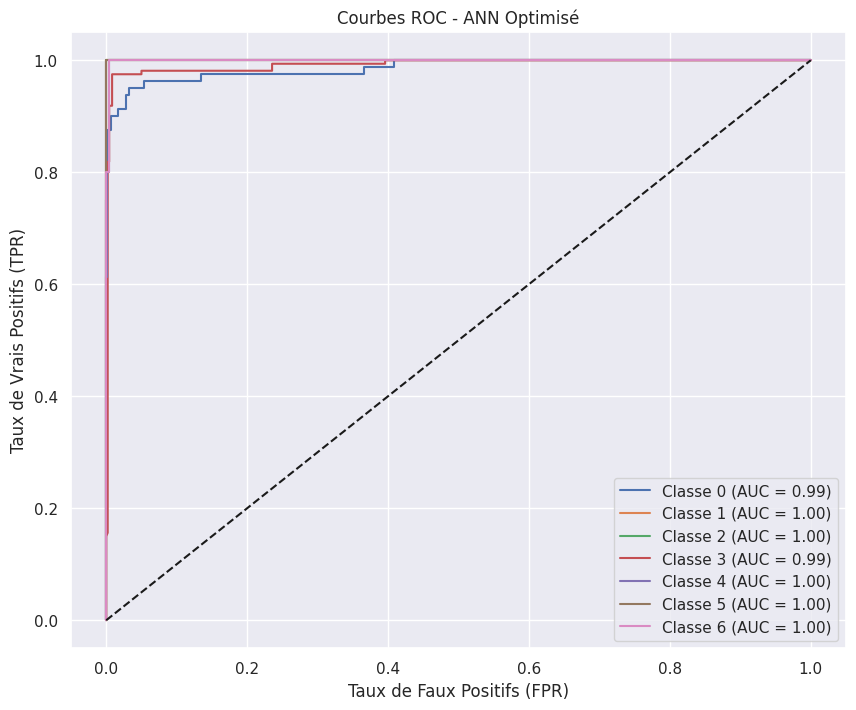

In [138]:
# Binarisation des labels pour le calcul de la courbe ROC
y_test_bin = label_binarize(y_test, classes=np.unique(y_test))
n_classes = y_test_bin.shape[1]

# Prédictions des probabilités par le modèle ANN optimisé
y_pred_proba = best_model.predict(X_test)

# Calcul des courbes ROC et des AUC pour chaque classe
fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_pred_proba[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Tracé des courbes ROC pour chaque classe
plt.figure(figsize=(10, 8))
for i in range(n_classes):
    plt.plot(fpr[i], tpr[i], label=f'Classe {i} (AUC = {roc_auc[i]:.2f})')

plt.plot([0, 1], [0, 1], 'k--')  # Diagonale
plt.xlabel("Taux de Faux Positifs (FPR)")
plt.ylabel("Taux de Vrais Positifs (TPR)")
plt.title("Courbes ROC - ANN Optimisé")
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

## Conclusion

"""
Après avoir entraîné et évalué plusieurs modèles, l'ANN optimisé avec Keras
Tuner a donné les meilleurs résultats avec une accuracy de **99%** pour les données de test.
Les visualisations des courbes d'apprentissage montrent une bonne convergence
et une absence de sur-apprentissage.

Le modèle final sera donc l'ANN optimisé, qui pourra être déployé pour la
classification des défauts sur les plaques d'acier.
"""

## Tableau récapitulatif de tout les modèles

In [139]:
# Calcul des métriques pour chaque modèle
metrics = {
    'Modèle': [],
    'Accuracy': [],
    'Precision': [],
    'Recall': [],
    'F1-Score': []
}

# Liste des modèles et leurs prédictions
models = {
    'K-Nearest Neighbors (KNN)': knn.predict(X_test),
    'Support Vector Machine (SVM)': svm.predict(X_test),
    'Decision Tree': decision_tree.predict(X_test),
    'Random Forest': rf.predict(X_test),
    'XGBoost': xgb(X_text),  # Prédictions calculées précédemment
    'Logistic Regression': logreg.predict(X_test),
    'Naive Bayes': naive_bayes.predict(X_test),
    'Artificial Neural Network (ANN)': np.argmax(model.predict(X_test), axis=1),
    'Optimized ANN (Keras Tuner)': np.argmax(best_model.predict(X_test), axis=1)
}

for model_name, y_pred in models.items():
    metrics['Modèle'].append(model_name)
    metrics['Accuracy'].append(accuracy_score(y_test, y_pred))
    metrics['Precision'].append(precision_score(y_test, y_pred, average='weighted', zero_division=0))
    metrics['Recall'].append(recall_score(y_test, y_pred, average='weighted'))
    metrics['F1-Score'].append(f1_score(y_test, y_pred, average='weighted'))

# Création d'un DataFrame
summary_table = pd.DataFrame(metrics).set_index('Modèle')

# Transposition du DataFrame pour inverser les axes
summary_table = summary_table.T

# Mise en forme pour afficher en gras le meilleur modèle pour chaque indicateur
def highlight_max(row):
    return ['font-weight: bold' if v == row.max() else '' for v in row]

styled_table = summary_table.style.apply(highlight_max, axis=1)

# Affichage du tableau récapitulatif
styled_table



20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


Modèle,K-Nearest Neighbors (KNN),Support Vector Machine (SVM),Decision Tree,Random Forest,XGBoost,Logistic Regression,Naive Bayes,Artificial Neural Network (ANN),Optimized ANN (Keras Tuner)
Accuracy,0.885938,0.779687,0.962500,0.976562,0.973437,0.765625,0.746875,0.900000,0.976562
Precision,0.882839,0.769466,0.962084,0.977533,0.974002,0.752555,0.743718,0.898288,0.977389
Recall,0.885938,0.779687,0.962500,0.976562,0.973437,0.765625,0.746875,0.900000,0.976562
F1-Score,0.881312,0.773546,0.962045,0.976108,0.972767,0.756265,0.742466,0.896799,0.976210


# Cross validation

/usr/local/lib/python3.10/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_7 (Dense)                      │ (None, 128)                 │           1,664 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_5 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_8 (Dense)                      │ (None, 256)                 │          33,024 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_6 (Dropout)                  │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_9 (Dense)                      │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_7 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_10 (Dense)                     │ (None, 7)                   │             903 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 68,487 (267.53 KB)

 Trainable params: 68,487 (267.53 KB)

 Non-trainable params: 0 (0.00 B)

... (25 outputs left out)

 Total params: 68,487 (267.53 KB)

 Trainable params: 68,487 (267.53 KB)

 Non-trainable params: 0 (0.00 B)

None
Validation croisée - Moyenne de l'accuracy: 0.9563 (+/- 0.0112)


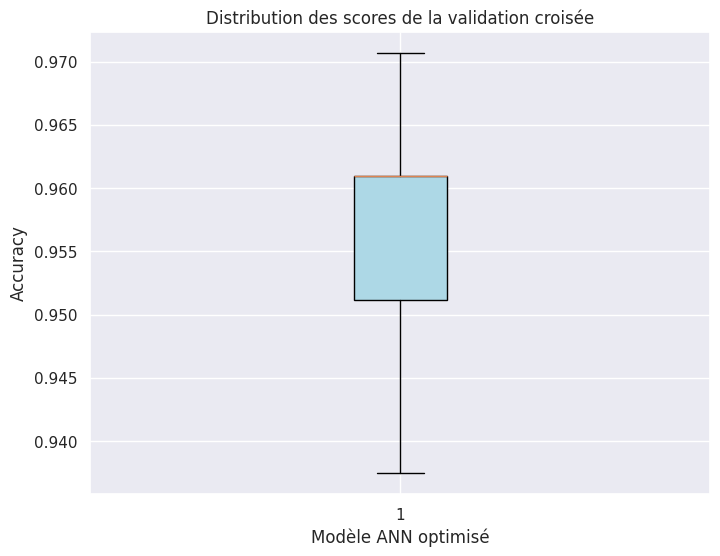

In [140]:
def create_best_model():
    model = Sequential()
    for i in range(best_hps.get('num_layers')):
        units = best_hps.get(f'units_{i}')
        activation = best_hps.get('activation')
        if i == 0:
            # Ajoutez input_shape ici pour la première couche uniquement
            if activation == 'leaky_relu':
                model.add(Dense(units, input_shape=(X_train.shape[1],)))
                model.add(LeakyReLU())
            elif activation == 'elu':
                model.add(Dense(units, input_shape=(X_train.shape[1],)))
                model.add(ELU())
            else:
                model.add(Dense(units, activation='relu', input_shape=(X_train.shape[1],)))
        else:
            # Ajoutez les couches suivantes normalement
            if activation == 'leaky_relu':
                model.add(Dense(units))
                model.add(LeakyReLU())
            elif activation == 'elu':
                model.add(Dense(units))
                model.add(ELU())
            else:
                model.add(Dense(units, activation='relu'))
        dropout_rate = best_hps.get(f'dropout_{i}')
        model.add(Dropout(rate=dropout_rate))

    # Ajouter la couche de sortie
    model.add(Dense(len(np.unique(y_train)), activation='softmax'))

    learning_rate = best_hps.get('learning_rate')
    model.compile(optimizer=Adam(learning_rate=learning_rate), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    print(model.summary())  # Vérification du modèle
    return model

# Wrapping the best model for cross-validation
best_ann_model = KerasClassifier(model=create_best_model, epochs=120, batch_size=32, verbose=0)

# Cross-validation
kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = cross_val_score(best_ann_model, X_train, y_train, cv=kfold, scoring='accuracy', error_score='raise')

# Affichage des résultats de la validation croisée
print(f"Validation croisée - Moyenne de l'accuracy: {results.mean():.4f} (+/- {results.std():.4f})")

# Affichage graphique des résultats
plt.figure(figsize=(8, 6))
plt.boxplot(results, vert=True, patch_artist=True, boxprops=dict(facecolor='lightblue'))
plt.title('Distribution des scores de la validation croisée')
plt.ylabel('Accuracy')
plt.xlabel('Modèle ANN optimisé')
plt.grid(True)
plt.show()


# Enregistrement des poids de tout les modèles ainsi que PCA et Scaler

In [142]:
# Exemple pour sauvegarder un StandardScaler
joblib.dump(scaler, 'scaler.pkl')

# Entraînez du PCA
pca = PCA(n_components=0.95)  # Exemple de PCA, ajusté sur 95% de la variance
X_train_pca = pca.fit_transform(X_scaled)
# Enregistrez l'instance de PCA
joblib.dump(pca, 'pca.pkl')

# Création du dossier principal 'weights' s'il n'existe pas
if not os.path.exists('weights'):
    os.makedirs('weights')

# Liste de vos modèles déjà entraînés (ajoutez les noms réels des modèles)
models = {
    "KNN": knn,  # Remplacez par l'objet de votre modèle KNN
    "SVM": svm,  # Remplacez par l'objet de votre modèle SVM
    "DecisionTree": decision_tree,  # Remplacez par votre modèle Decision Tree
    "RandomForest": rf,  # Remplacez par votre modèle Random Forest
    "XGBoost": xgb,  # Remplacez par votre modèle XGBoost
    "LogisticRegression": logreg,  # Remplacez par Logistic Regression
    "NaiveBayes": naive_bayes,  # Remplacez par Naive Bayes
    "ANN": best_model  # Remplacez par votre modèle ANN
}


# Boucle pour sauvegarder les modèles
for model_name, model in models.items():
    # Création d'un sous-dossier pour chaque modèle
    model_folder = os.path.join('weights', model_name)
    if not os.path.exists(model_folder):
        os.makedirs(model_folder)

    if model_name == "ANN":
        # Sauvegarde des poids pour les modèles Keras (ANN)
        if hasattr(model, 'save_weights'):
            model.save_weights(os.path.join(model_folder, 'model.weights.h5'))
        else:
            print(f"Le modèle {model_name} ne peut pas être enregistré avec save_weights().")
    else:
        # Pour tous les autres modèles (y compris XGBoost de type scikit-learn)
        model_path = os.path.join(model_folder, f"{model_name}_model.pkl")
        try:
            joblib.dump(model, model_path)
        except:
            pass

print("Tous les modèles pris en charge ont été sauvegardés.")

Tous les modèles pris en charge ont été sauvegardés.
